# Анализ венчурного рынка и оценка инвестиционной привлекательности стартапов

**Автор:** Затула Денис Викторович  
**Дата:** 29.07.2026

## Введение

#### Контекст и цели проекта

Проект выполняется в интересах инвестора и посвящён исследованию рынка стартапов
на основе данных из базы Crunchbase. Анализ проводится на «срезе» 2015 года:
заказчику необходимо принять решение о направлении дальнейших инвестиций и понять,
какой тип финансирования будет уместен.

**Цель проекта** — на основе исторических данных о стартапах сформулировать
обоснованную рекомендацию:
* в какую отрасль (сегмент рынка) стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

**Используемые данные**
* `cb_investments.csv` (основной датасет) — сведения о компаниях-стартапах:
  идентификаторы, география, сегмент рынка (`market`), общий объём и число раундов
  финансирования, даты основания и раундов, а также суммы по 13 типам финансирования
  (`seed`, `venture`, `debt_financing`, `private_equity`, `angel` и др.).
* `cb_returns.csv` (дополнительный датасет) — суммы возвратов по типам финансирования
  по годам (в миллионах долларов); используется для оценки окупаемости.

**Этапы работы**
1. **Знакомство с данными и предобработка.** Загрузка датасетов, осмотр пропусков
   и типов, приведение названий столбцов к единому стилю, преобразование типов
   (`funding_total_usd` → numeric, даты → `Period`/`Datetime`), обработка пропусков
   и дубликатов, согласованность временных признаков. Контроль качества ведётся через
   вспомогательный датафрейм `comparison_df` (сравнение «до/после» каждого шага).
2. **Инжиниринг признаков.** Разделение компаний на группы по срокам финансирования
   (единичное / до года / более года) и сегментация рынка (`market`) на массовые,
   средние и нишевые.
3. **Работа с выбросами и анализ.** Графическая оценка типичного размера
   финансирования, выявление аномалий методом IQR по сегментам, проверка полноты
   данных за 2014 год, сравнение типов финансирования по объёму и популярности.
4. **Анализ динамики.** Динамика среднего размера раунда и числа раундов по годам,
   сводная по массовым растущим сегментам, нормированный показатель возврата средств
   по типам финансирования.
5. **Итоговый вывод и рекомендации.** Сводка результатов и итоговая рекомендация
   заказчику по отрасли и типу финансирования.

## 1. Загрузка данных и предобработка

Исходные данные выгружены из базы стартапов Crunchbase в директорию `../datasets/` (`cb_investments.csv` и `cb_returns.csv`).

Основные поля `cb_investments.csv`: `name`, `homepage_url`, `category_list`, `market`, `funding_total_usd`, `status`, `country_code`, `state_code`, `region`, `city`, `funding_rounds`, `participants`, `founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at`, а также суммы по типам финансирования (`seed`, `venture`, `debt_financing`, `angel`, `private_equity` и др.) и раундам (`round_A`–`round_H`).

Дополнительный файл `cb_returns.csv` содержит ежегодные суммарные объемы возврата средств (млн USD) по типам финансирования.

### 1.1. Вывод общей информации

In [1]:
# Импортируем библиотеки для работы с данными:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Настройка стиля Seaborn для всех графиков ноутбука
sns.set_theme(style="whitegrid")

#### 1.1.1. Загрузка cb_investments

In [3]:
# Загрузка основного датасета cb_investments из локального CSV-файла
df_invest = pd.read_csv("../datasets/cb_investments.csv", sep=';', low_memory=False)
df_invest.info()

<class 'pandas.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  str    
 1   homepage_url          45989 non-null  str    
 2   category_list         45477 non-null  str    
 3    market               45477 non-null  str    
 4    funding_total_usd    49438 non-null  str    
 5   status                48124 non-null  str    
 6   country_code          44165 non-null  str    
 7   state_code            30161 non-null  str    
 8   region                44165 non-null  str    
 9   city                  43322 non-null  str    
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  str    
 13  founded_month         38482 non-null  str    
 14  founded_quarter       38482 non-null  str    
 15  founded_year          38554 no

In [4]:
# Первые пять строк датасета cb_investments
df_invest.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### 1.1.2 Загрузка cb_return

In [5]:
# Загрузка дополнительного датасета cb_returns и первичный осмотр
df_return = pd.read_csv("../datasets/cb_returns.csv", sep=',', low_memory=False)
df_return.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


In [6]:
# Все 15 строк cb_returns
df_return.head(15)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
1,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
4,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
5,2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
6,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
7,2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
8,2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00
9,2009,160.21,2501.29,0.18,37.50,2.25,394.10,97.21,0.0,203.70,76.76,0.00,0.12,0.02


#### 1.1.3 Анализ информации по датасетам (нужна для предобработки)

In [7]:
# Количество столбцов и строк в Датафреймах:
print(f'Количество строк и столбцов df_invest: {df_invest.shape}')
print(f'Количество строк и столбцов df_return: {df_return.shape}')

Количество строк и столбцов df_invest: (54294, 40)
Количество строк и столбцов df_return: (15, 14)


df_return является датасетом с набором статистики и содержит всего 15 значений, поэтому дальше рассмотрим df_invest

In [8]:
# Структура данных текущего датафрейма df_invest
df_invest.info()

<class 'pandas.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  str    
 1   homepage_url          45989 non-null  str    
 2   category_list         45477 non-null  str    
 3    market               45477 non-null  str    
 4    funding_total_usd    49438 non-null  str    
 5   status                48124 non-null  str    
 6   country_code          44165 non-null  str    
 7   state_code            30161 non-null  str    
 8   region                44165 non-null  str    
 9   city                  43322 non-null  str    
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  str    
 13  founded_month         38482 non-null  str    
 14  founded_quarter       38482 non-null  str    
 15  founded_year          38554 no

In [9]:
# Столбцы с пробелами в названиях (требуют переименования)
print(f'Столбцы df_invest, которые нужно переименовать: {[x for x in df_invest.columns if " " in x]}')
print(f'Столбцы df_return, которые нужно переименовать: {[x for x in df_return.columns if " " in x]}')

Столбцы df_invest, которые нужно переименовать: [' market ', ' funding_total_usd ']
Столбцы df_return, которые нужно переименовать: []


- Запустив df_invest.info(), заметил, что общее количество строк Датафрейма df_invest составляет 54294 строки, однако в перечисленных полях нет ни одного столбца, который был бы заполнен полностью, например в поле `name` отсутствуют значения в ~5000 строк. Максимальное количество заполненных записей составляет максимум 49438. В связи с этим предполагаю, что в Датафрейме  df_invest есть полностью пустые строки. Построю heatmap, чтобы проверить эту гипотезу.

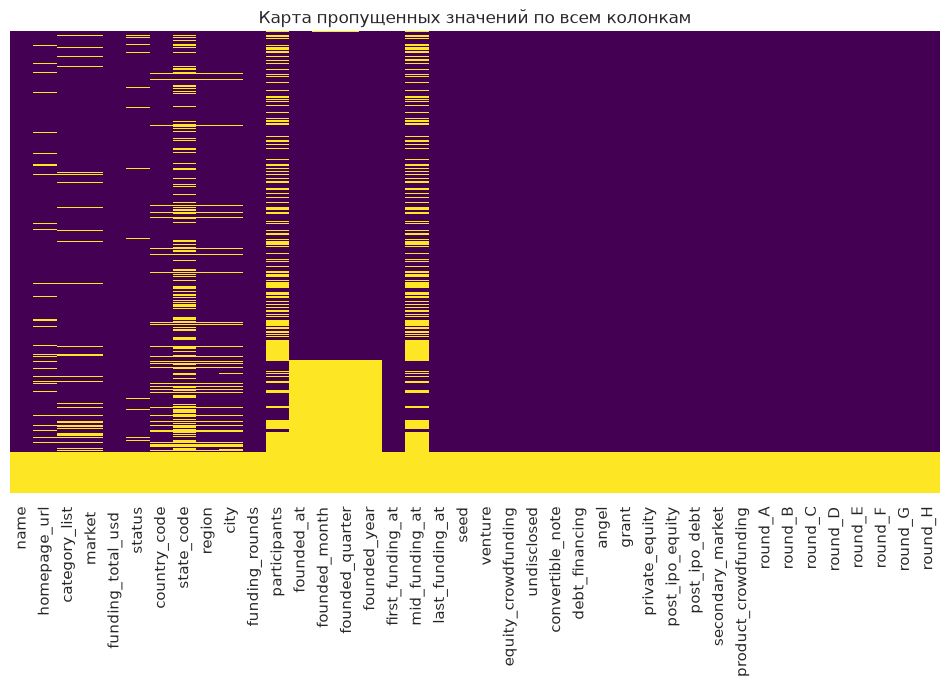

In [10]:
# Тепловая карта пропусков для df_invest:
plt.figure(figsize=(12, 6))
# cbar=False убирает цветовую шкалу, так как значений всего два (True/False)
sns.heatmap(df_invest.isna(), cmap='viridis', cbar=False, yticklabels=False)
plt.title('Карта пропущенных значений по всем колонкам')
plt.show()

Гипотеза о наличии полностью пустых строк подтверждается, они указаны сплошным жёлтым цветом по горизонтали внизу графика

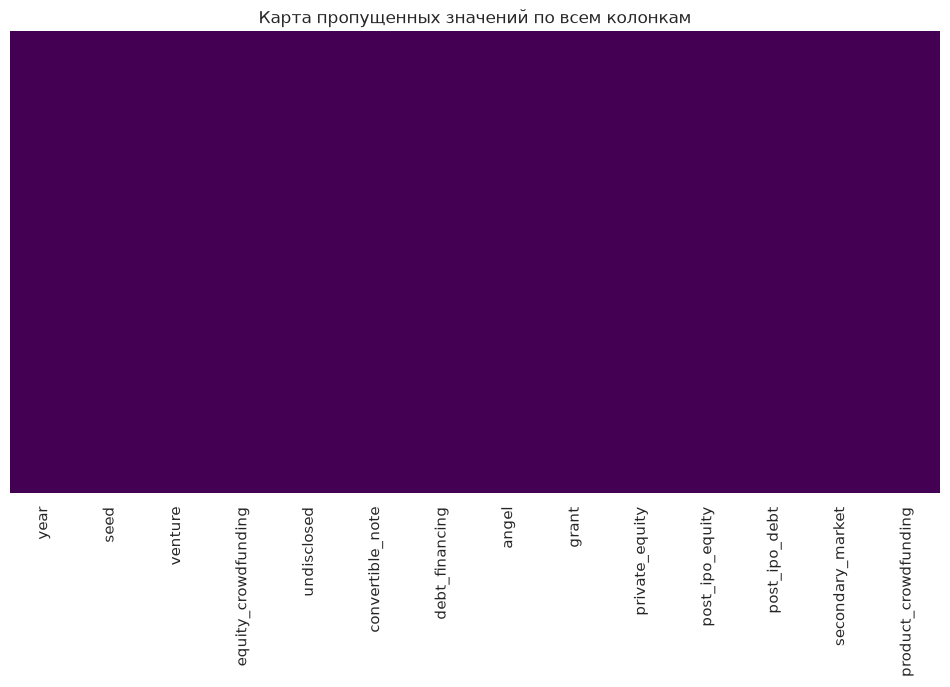

In [11]:
# Тепловая карта пропусков для df_return:
plt.figure(figsize=(12, 6))
# cbar=False убирает цветовую шкалу, так как значений всего два (True/False)
sns.heatmap(df_return.isna(), cmap='viridis', cbar=False, yticklabels=False)
plt.title('Карта пропущенных значений по всем колонкам')
plt.show()

In [12]:
# Выводим столбцы, которые предположительно нужно привести к datetime:
print(f'Столбцы df_invest, которые нужно привести к типу datetime: {[x for x in df_invest.columns if "_at" in x]}')

Столбцы df_invest, которые нужно привести к типу datetime: ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']


In [13]:
# Выводим колонки которые предположительно datetime:
df_invest[['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']]

,founded_at,first_funding_at,mid_funding_at,last_funding_at
0,1636-09-08,2014-01-06,NaN,2014-01-06
1,1785-01-01,2014-05-15,NaN,2014-05-15
2,1802-07-19,2009-07-02,2009-07-02,2009-07-02
3,1817-01-01,2013-11-21,2013-11-21,2014-11-03
4,1826-01-01,2014-01-14,NaN,2014-01-14
...,...,...,...,...
54289,NaN,NaN,NaN,NaN
54290,NaN,NaN,NaN,NaN
54291,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN


Для отслеживания количества полей по колонкам создадим `comparison_df` и сохраним в него
информацию о количестве нулевых значений.
- `nulls_initial` - изначальное количество пустых значений в каждом столбце Датафрейма `df_invest`
- `rows_initial` - изначальное количество строк в Датафрейме `df_invest`

In [14]:
# Создаём вспомогательный датафрейм для фиксации исходного количества пропусков
# и общего числа строк в каждой колонке перед началом предобработки.

comparison_df = pd.DataFrame({
    'column_name': df_invest.columns.tolist(),
    'nulls_initial': df_invest.isna().sum().values,
    'rows_initial': df_invest.shape[0]
})

comparison_df.sort_values(by=['nulls_initial'], ascending=False)

,column_name,nulls_initial,rows_initial
7,state_code,24133,54294
17,mid_funding_at,24006,54294
11,participants,23821,54294
14,founded_quarter,15812,54294
13,founded_month,15812,54294
15,founded_year,15740,54294
12,founded_at,15740,54294
9,city,10972,54294
6,country_code,10129,54294
8,region,10129,54294


#### 1.1.4. Вывод по анализу пропусков

В исходном датасете `df_invest` присутствует значительное количество пропусков, и они распределены неравномерно по столбцам. Наибольшее число пропусков наблюдается в признаках, связанных с датой основания компании, параметрами финансирования и географическими признаками, например `state_code`, `mid_funding_at`, `participants`, `founded_at`, `founded_year`, `founded_month` и `founded_quarter`.

Меньше всего пропусков — в базовых идентификаторах компании и части финансовых признаков, однако даже в них есть незаполненные значения, что говорит о неполной структуре исходных данных.

Особенно важно, что:
- часть временных признаков заполнена не полностью;
- `funding_total_usd` и связанные с ним поля имеют пропуски в одном и том же объёме;
- это указывает на строки, где отсутствует информация о финансировании вообще;
- признаки `founded_at`, `founded_year`, `founded_month` и `founded_quarter` содержат согласованные по смыслу, но неполные данные, что потребует отдельной обработки.

Также при первичном осмотре данных также стоит обратить внимание на названия столбцов. Часть из них содержит лишние пробелы или оформлена не в самом удобном для анализа стиле, поэтому перед дальнейшей работой названия были приведены к более аккуратному виду. Это упрощает обращение к колонкам, снижает риск ошибок в коде и делает ноутбук более читаемым.


Таким образом, данные нельзя использовать для анализа без предварительной очистки. На следующем этапе необходимо:
- переимновать столбцы для более удобного анализа;
- удалить полностью пустые строки;
- привести типы данных;
- обработать строки без информации о финансировании;
- поиск дубликатов;
- отдельно разобраться с временными признаками и их согласованностью.

### 1.2. Предобработка данных

#### 1.2.1. Переименование столбцов Датафрейма df_invest():

In [15]:
# Показываем столбцы Датафрейма df_invest, которые будем переименовывать:
# (повтор проверки — после переименования проверяем, что пробелов в названиях не осталось)
print(f'Столбцы df_invest, которые нужно переименовать: {[x for x in df_invest.columns if " " in x]}')

Столбцы df_invest, которые нужно переименовать: [' market ', ' funding_total_usd ']


In [16]:
def rename_columns():
    """
    Приводит названия столбцов Датафрейма df_invest к аккуратному единому стилю:
    удаляет лишние пробелы в начале и конце имён колонок (strip).

    Назначение: стадия предобработки — корректные имена столбцов
    упрощают дальнейшее обращение к колонкам и снижают риск ошибок в коде.

    Внимание: мутирует глобальный df_invest inplace (использует глобальную ссылку
    на df_invest и rename(inplace=True)). Возвращает None, результат печати —
    словарь замен {old_name: new_name}.
    """
    old_col_list = [x for x in df_invest.columns if " " in x]
    new_col_list = [x.strip() for x in old_col_list]
    col_dict = dict(zip(old_col_list, new_col_list))
    df_invest.rename(columns=col_dict, inplace=True)
    print(f'Столбцы переименованы: {col_dict}')

rename_columns()
# Приводим имена столбцов в comparison_df к актуальному виду после rename:
comparison_df['column_name'] = comparison_df['column_name'].str.strip()

Столбцы переименованы: {' market ': 'market', ' funding_total_usd ': 'funding_total_usd'}


/tmp/ipykernel_4619/1560427134.py:16: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_invest.rename(columns=col_dict, inplace=True)


#### 1.2.2. Преобразование типов датафрейма df_invest (cb_investments)

In [17]:
# Выводим первые 15 строк столбца funding_total_usd до преобразования в numeric:
df_invest['funding_total_usd'].head(15)

0      9,00,00,000 
1        20,00,000 
2        90,00,000 
3        77,00,000 
4         5,40,000 
5      1,90,00,000 
6      1,20,00,000 
7        87,00,000 
8        60,00,000 
9        35,00,000 
10     2,80,00,000 
11       27,05,000 
12       89,00,000 
13             -   
14       80,00,000 
Name: funding_total_usd, dtype: str

**Промежуточный вывод по увиденному**: *В столбце `funding_total_usd` встречается нестандартное для европейского формата разделение разрядов: числа могут быть записаны в индийской системе. Поэтому перед преобразованием в числовой тип мы удаляем все разделители, чтобы избежать ошибок при парсинге.*

In [18]:
# Фиксируем число пропусков до преобразования, чтобы затем оценить,
# появились ли новые NaN после приведения к числовому типу
funding_total_usd_before_numeric = df_invest['funding_total_usd'].isna().sum()
print(f"Количество пропусков до преобразования в numeric: {funding_total_usd_before_numeric}")

Количество пропусков до преобразования в numeric: 4856


In [19]:
# Создаем маску: regex [^\d.,\s] ищет символы, НЕ являющиеся цифрой (\d),
# точкой, запятой или пробелом (\s) — то есть мусорные символы, которые
# упадут при последующем pd.to_numeric(..., errors='coerce').
mask = df_invest['funding_total_usd'].str.contains(r'[^\d.,\s]', regex=True, na=False)

# Применяем маску к датафрейму и выводим результат
rows_with_special_chars = df_invest[mask]

# Сводное число строк с мусорными символами:
print(f'Найдено значений с мусорными символами: {int(mask.sum())}')
# Чтобы посмотреть на сами значения с проблемными символами:
rows_with_special_chars['funding_total_usd'].value_counts()

Найдено значений с мусорными символами: 8531


funding_total_usd
-       8531
Name: count, dtype: int64

Навскидку есть 8531 значение, которое не может быть преобразовано в numeric type. Ниже проверим предположение

In [20]:
# Убираем разделители разрядов и пробелы, чтобы подготовить строковые значения
# к корректному преобразованию в число.
df_invest['funding_total_usd'] = (
    df_invest['funding_total_usd']
    .str.replace(',', '', regex=False)
    .str.replace(' ', '', regex=False)
)

In [21]:
# Приводим столбец к числовому типу.
# Некорректные значения будут заменены на NaN, и мы сможем оценить их количество.
# TODO(точность): downcast='float' даёт float32 — возможна потеря точности для
# крупных сумм в USD; рассмотреть снятие downcast.
numeric_cols = ['funding_total_usd']
for col in numeric_cols:
    df_invest[col] = pd.to_numeric(df_invest[col], errors='coerce', downcast='float')
print("Типы данных после преобразования:")
print(df_invest[numeric_cols].dtypes)

Типы данных после преобразования:
funding_total_usd    float64
dtype: object


In [22]:

# Сравниваем количество пропусков до и после преобразования,
# чтобы понять, какие значения не удалось восстановить.
funding_total_usd_after_numeric = df_invest['funding_total_usd'].isna().sum()
print(f"Количество пропусков до преобразования в numeric: {funding_total_usd_before_numeric}")
print(f'Количество пропусков после преобразования в numeric: {funding_total_usd_after_numeric}')
print(f'Разница после - до: {funding_total_usd_after_numeric - funding_total_usd_before_numeric}')

Количество пропусков до преобразования в numeric: 4856
Количество пропусков после преобразования в numeric: 13387
Разница после - до: 8531


*Промежуточный вывод: Применяя `errors='coerce'` для преобразования в numeric колонки `funding_total_usd` гипотеза подтвердилась - мы нашли все мусорные значения, которые для дальнейшего анализа не несут никакой ценности*

- Cтолбец `founded_at` делаем типом PeriodIndex, поскольку есть значения ниже 1970 года(старые даты до UNIX)

In [23]:
# Обрабатываем типы данных в столбце founded_at:
# Преобразуем столбцы c типом данных object в правильный тип данных:
period_cols = ['founded_at']
# Создадим Датафрейм для учёта количества строк и типов столбцов из списка period_cols:
# Слепок до преобразования(типы и количество notnull строк):
info_df = pd.DataFrame({
    'column_name': df_invest[period_cols].columns,
    'old_not_null_count': df_invest[period_cols].notna().sum().values,
    'old_dtype': df_invest[period_cols].dtypes.values
})
# Напишем цикл, который на входе будет принимать значение столбцов и переводить в тип PeriodIndex:
for col in period_cols:
    df_invest[col] = pd.PeriodIndex(df_invest[col], freq='D')
# Слепок после преобразования(типы и количество notnull строк):
info_df['new_not_null_count'] = df_invest[period_cols].notna().sum().values
info_df['new_dtype'] = df_invest[period_cols].dtypes.values
# Считаем разницу количество строк после - количество строк до:
info_df['row_diff'] = info_df['new_not_null_count'] - info_df['old_not_null_count']
info_df.sort_values(by=['row_diff'], ascending=True, inplace=True)
info_df.reset_index(drop=True, inplace=True)
print(f'Слепок типов и числа notnull по founded_at до/после преобразования в PeriodIndex:\n{info_df}')

Слепок типов и числа notnull по founded_at до/после преобразования в PeriodIndex:
  column_name  old_not_null_count old_dtype  new_not_null_count  new_dtype  \
0  founded_at               38554       str               38554  period[D]   

   row_diff  
0         0  


/tmp/ipykernel_4619/3960929146.py:19: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  info_df.sort_values(by=['row_diff'], ascending=True, inplace=True)
/tmp/ipykernel_4619/3960929146.py:20: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  info_df.reset_index(drop=True, inplace=True)


В столбце `founded_at` не было изменений по количеству notnull строк

- Cтолбцы `first_funding_at`, `mid_funding_at`, `last_funding_at` делаем типом Datetime, поскольку значения больше 1970 года и есть большая вероятность, что данные значения придётся сравнивать и анализировать, поэтому Datetime здесь необходим

In [24]:
# Обрабатываем типы данных в столбцах first_funding_at, mid_funding_at, last_funding_at:
# Преобразуем столбцы c типом данных object в правильный тип данных:
datetime_cols = ['first_funding_at', 'mid_funding_at', 'last_funding_at']
# Создадим Датафрейм для учёта количества строк и типов столбцов из списка datetime_cols:
# Слепок до преобразования(типы и количество notnull строк):
info_df = pd.DataFrame({
    'column_name': df_invest[datetime_cols].columns,
    'old_not_null_count': df_invest[datetime_cols].notna().sum().values,
    'old_dtype': df_invest[datetime_cols].dtypes.values
})
# Напишем цикл, который на входе будет принимать значение столбцов и переводить в тип Datetime:
for col in datetime_cols:
    df_invest[col] = pd.to_datetime(df_invest[col], errors='coerce')
# Слепок после преобразования(типы и количество notnull строк):
info_df['new_not_null_count'] = df_invest[datetime_cols].notna().sum().values
info_df['new_dtype'] = df_invest[datetime_cols].dtypes.values
# Считаем разницу количество строк после - количество строк до:
info_df['row_diff'] = info_df['new_not_null_count'] - info_df['old_not_null_count']
info_df.sort_values(by=['row_diff'], ascending=True, inplace=True)
info_df.reset_index(drop=True, inplace=True)
print(f'Слепок типов и числа notnull по датам финансирования до/после преобразования в Datetime:\n{info_df}')

Слепок типов и числа notnull по датам финансирования до/после преобразования в Datetime:
        column_name  old_not_null_count old_dtype  new_not_null_count  \
0  first_funding_at               49438       str               49438   
1    mid_funding_at               30288       str               30288   
2   last_funding_at               49438       str               49438   

        new_dtype  row_diff  
0  datetime64[us]         0  
1  datetime64[us]         0  
2  datetime64[us]         0  


/tmp/ipykernel_4619/1756416384.py:19: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  info_df.sort_values(by=['row_diff'], ascending=True, inplace=True)
/tmp/ipykernel_4619/1756416384.py:20: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  info_df.reset_index(drop=True, inplace=True)


- В столбцах `first_funding_at`, `last_funding_at` были изменения по количеству notnull строк: 10 и 6 соответственно, в столбце `mid_funding_at` изменений по количеству notnull строк не было

Перед тем как поставить errors='coerce', пробовал запустить преобразование с errors='raise' и нашел 3 паттерна:


- 1. Когда значение похоже на реальное и имело вид '00DD-MM-YY' и было хронологически согласованно с mid_funding_at:


```python
df_invest.loc[38554, ['first_funding_at', 'mid_funding_at', 'last_funding_at']]
# Возвращает  0001-07-14, однако мы не можем сто процентов утверждать что это = '2014-07-01', однако паттерн 00DD-MM-YY прослеживается
```


- 2. Когда значение мусор, но mid_funding_at = last_funding_at:


```python
df_invest.loc[2177, 'first_funding_at'] = '2012-07-24'
# Встретилось '0019-11-20', однако last и mid = 2012-07-24
df_invest.loc[31854, 'first_funding_at'] = '2013-06-01'
# Встретилось 0007-05-13, однако last и mid = 2013-06-01
```


- 3. Когда перед нами мусор и такие значения нужно обнулять в связи с невозможностью восстановления:


```python
# Ячейки с полным мусором, которым действительно нужно превратить в NaN/NaT
df_invest.loc[33041, ['first_funding_at', 'mid_funding_at', 'last_funding_at']] = [np.nan, np.nan, np.nan]
df_invest.loc[37546, ['first_funding_at', 'mid_funding_at', 'last_funding_at']] = [np.nan, np.nan, np.nan]
df_invest.loc[38506, ['first_funding_at', 'mid_funding_at', 'last_funding_at']] = [np.nan, np.nan, np.nan]
```


Учитывая незначительность таких ошибок - принял решение применить errors='coerce', зафиксирую на будущее подобные проблемы в значениях дат

In [25]:
# Выведем 15 первых строк столбцов founded_at, first_funding_at, mid_funding_at, last_funding_at после преобразования:
df_invest[['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']].head(15)

,founded_at,first_funding_at,mid_funding_at,last_funding_at
0,1636-09-08,2014-01-06,NaT,2014-01-06
1,1785-01-01,2014-05-15,NaT,2014-05-15
2,1802-07-19,2009-07-02,2009-07-02,2009-07-02
3,1817-01-01,2013-11-21,2013-11-21,2014-11-03
4,1826-01-01,2014-01-14,NaT,2014-01-14
5,1831-01-01,2014-10-23,NaT,2014-10-23
6,1834-01-01,2013-09-05,2013-09-05,2013-12-22
7,1838-01-01,2014-01-12,NaT,2014-01-12
8,1838-01-01,2014-09-30,NaT,2014-09-30
9,1840-01-01,2007-10-01,2007-10-01,2008-03-01


In [26]:
# Приведём год к типу datetime и сделаем year индексом df_return
df_return.set_index('year', inplace=True)

/tmp/ipykernel_4619/499293669.py:2: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_return.set_index('year', inplace=True)


#### 1.2.3. Работа с пропусками и дубликатами df_invest (cb_investments)

В пункте 1.1.3 выяснили, что есть абсолютно пустые строки, сначала удалим их

In [27]:
# Фиксируем количество строк до удаления:
rows_before = df_invest.shape[0]
print(f'Изначальное количество строк : {rows_before}')

Изначальное количество строк : 54294


In [28]:
# Посчитаем относительное количество пропусков в Датафрейме df_invest:
comparison_df['nulls_initial_percent'] = np.round(comparison_df['nulls_initial'] / comparison_df['rows_initial'] * 100, decimals=2)
comparison_df.sort_values(by='nulls_initial_percent', ascending=False)

,column_name,nulls_initial,rows_initial,nulls_initial_percent
7,state_code,24133,54294,44.45
17,mid_funding_at,24006,54294,44.21
11,participants,23821,54294,43.87
14,founded_quarter,15812,54294,29.12
13,founded_month,15812,54294,29.12
15,founded_year,15740,54294,28.99
12,founded_at,15740,54294,28.99
9,city,10972,54294,20.21
6,country_code,10129,54294,18.66
8,region,10129,54294,18.66


***Вывод по первоначальным пропускам***: На этапе первичного анализа видно, что датасет `df_invest` содержит заметное количество пропусков: в общей сложности объем неполных значений составляет значимую долю от всех ячеек таблицы, а распределение пропусков по столбцам сильно неравномерно.  

По уровню проблемы признаки можно условно разделить на несколько групп:

- **Критически проблемные поля** — в них пропущено около 30–45% значений. К этой группе относятся `state_code` (примерно 44.45%), `mid_funding_at` (около 44.21%), `participants` (около 43.87%), а также признаки, связанные с датой основания: `founded_at`, `founded_year`, `founded_month`, `founded_quarter` (примерно 28.99–29.12%). Такие пропуски уже могут сильно влиять на анализ и требуют отдельной обработки.

- **Средне проблемные поля** — пропуски находятся на уровне примерно 10–20%. Сюда входят `city` (около 20.21%), `country_code` и `region` (по 18.66%), `category_list` и `market` (по 16.24%), `homepage_url` (около 15.30%), `status` (около 11.36%). Эти признаки важны для сегментации и интерпретации данных, поэтому их тоже нельзя игнорировать.

- **Относительно стабильные поля** — в них доля пропусков меньше 10%, но они все равно требуют проверки. Например, `name` имеет около 8.95% пропусков, а большинство финансовых признаков (`seed`, `venture`, `angel`, `grant`, `debt_financing` и другие) имеют примерно по 8.94% пропусков. Это может означать, что часть компаний не участвовала в соответствующем типе финансирования, либо информация не была зафиксирована.

Особенно важно, что у группы финансовых признаков число пропусков совпадает, а значит, это, скорее всего, одни и те же строки, где отсутствует вся информация о раундах финансирования. Такие записи будут отдельно обработаны на следующих этапах.

В целом данные нельзя считать готовыми к анализу без предобработки: сначала нужно устранить пустые строки, привести типы, а затем отдельно разобраться с пропусками в ключевых признаках.  

In [29]:
# Удаляем пустые строки:
df_invest.dropna(how='all', inplace=True)
# Проверяем количество строк после удаления пустых строк:
rows_after_dropna_all = df_invest.shape[0]
print(f'Количество строк после удаления пустых строк : {rows_after_dropna_all}')

Количество строк после удаления пустых строк : 49438


/tmp/ipykernel_4619/281335226.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_invest.dropna(how='all', inplace=True)


Добавляем в Датафрейм `comparison_df` новые столбцы:
- `nulls_after_dropempty` - Количество пустых значений в каждом столбце Датафрейма `df_invest` после удаления пустых строк
- `rows_after_dropempty` - Количество строк в Датафрейме `df_invest` после удаления пустых строк
- `nulls_after_dropempty_percent` - Доля нулевых значений относительно `rows_after_dropempty`
- `diff_rows_dropempty_initial` - Разница `rows_after_dropempty` и `rows_initial`
- `diff_nulls_dropempty_initial` - Разница `nulls_after_dropempty` и `nulls_initial`

In [30]:
# Считаем количество пустых значений по колонками после удаления пустых строк
comparison_df['nulls_after_dropempty'] = df_invest.isna().sum().values
comparison_df['rows_after_dropempty'] = len(df_invest)
comparison_df['nulls_after_dropempty_percent'] = np.round(comparison_df['nulls_after_dropempty'] / comparison_df['rows_after_dropempty'] * 100, decimals=2)
comparison_df['diff_rows_dropempty_initial'] = comparison_df['rows_after_dropempty'] - comparison_df['rows_initial']
comparison_df['diff_nulls_dropempty_initial'] = comparison_df['nulls_after_dropempty'] - comparison_df['nulls_initial']
comparison_df.set_index('column_name')[['nulls_initial', 'nulls_after_dropempty', 'nulls_after_dropempty_percent', 'diff_nulls_dropempty_initial']]

,nulls_initial,nulls_after_dropempty,nulls_after_dropempty_percent,diff_nulls_dropempty_initial
column_name,,,,
name,4857,1,0.00,-4856
homepage_url,8305,3449,6.98,-4856
category_list,8817,3961,8.01,-4856
market,8817,3961,8.01,-4856
funding_total_usd,4856,8531,17.26,3675
status,6170,1314,2.66,-4856
country_code,10129,5273,10.67,-4856
state_code,24133,19277,38.99,-4856
region,10129,5273,10.67,-4856


Датафрейм `comparison_df` используется для мониторинга изменений количества пропусков в данных по мере проведения предобработки. Он позволяет сравнивать ситуацию «до» и «после» разных шагов очистки и заполнения.
**Столбцы:**
- `rows_fillna` — количество строк в датафрейме `df_invest` на момент после заполнения пропусков Это общая численность наблюдений, используемая как базовый масштаб для расчёта долей.
- `nulls_fillna` — суммарное количество пропусков (`NaN`) по всем колонкам в `df_invest` после выполнения операции `fillna`. Показывает текущий объём «пустых» значений.
- `diff_nulls_fillna_dropempty` — разница между количеством пропусков после заполнения (`nulls_fillna`) и количеством пропусков после удаления «пустых» строк (`nulls_after_dropempty`). Позволяет оценить, сколько пропусков было устранено за счёт удаления строк без информации
- `diff_nulls_fillna_initial` — разница между текущим количеством пропусков (`nulls_fillna`) и исходным количеством пропусков (`nulls_initial`). Показывает, насколько снизился объём пропусков в результате всех проведённых преобразований по сравнению с исходным состоянием данных.
- `nulls_fillna_percent` — доля пропусков относительно общего числа строк на текущем этапе: `nulls_fillna / rows_fillna * 100`. Выражается в процентах и позволяет оценить, насколько «чистыми» являются данные после выполненных шагов предобработки. Чем ниже значение, тем меньше пропусков осталось в датасете.

In [31]:
def count_fillna():
    """
    Обновляет вспомогательный датафрейм comparison_df после очередного этапа обработки пропусков.

    Функция пересчитывает текущее количество строк в df_invest, суммарное число пропусков
    по каждому столбцу, а также разницы между текущим уровнем пропусков и исходными
    значениями до начала предобработки и после удаления полностью пустых строк.

    Добавляемые/обновляемые показатели:
    - rows_fillna: текущее количество строк в df_invest;
    - nulls_fillna: текущее количество пропусков в каждом столбце;
    - diff_nulls_fillna_dropempty: разница между текущим числом пропусков и числом пропусков
      после удаления полностью пустых строк;
    - diff_nulls_fillna_initial: разница между текущим числом пропусков и исходным числом
      пропусков;
    - nulls_fillna_percent: доля пропусков в процентах от общего числа строк.

    Внимание: обновляет глобальный comparison_df inplace (использует глобальные ссылки
    на comparison_df и df_invest).

    Функция используется как инструмент контроля качества данных на этапах предобработки.
    """
    # Считаем разницу:
    comparison_df['rows_fillna'] = df_invest.shape[0]
    comparison_df['nulls_fillna'] = df_invest.isna().sum().values
    comparison_df['diff_nulls_fillna_dropempty'] = comparison_df['nulls_fillna'] - comparison_df['nulls_after_dropempty']
    comparison_df['diff_nulls_fillna_initial'] = comparison_df['nulls_fillna'] - comparison_df['nulls_initial']
    # Создаём столбец в котором посчитаем относительное количество строк от
    comparison_df['nulls_fillna_percent'] = (comparison_df['nulls_fillna'] / comparison_df['rows_fillna'] * 100).round(2)

In [32]:
# Определяем колонки с типом данных "Строка" для проставления заглушек
# Маппинг вида "Колонка -> Значение-заглушка"
fillna_dict = {
    'name': '',
    'homepage_url': '',
    'category_list': '',
    'status': '',
    'country_code': '',
    'state_code': '',
    'region': '',
    'city': '',
    'market': 'UNKNOWN'
}

# Применяем fillna
df_invest = df_invest.fillna(value=fillna_dict)
count_fillna()
# df_invest.dropna(subset=['market'], inplace=True)

In [33]:
# Выводим результат (можно отсортировать по diff для наглядности)
comparison_df.set_index('column_name')\
    [['nulls_initial',
      'nulls_fillna',
      'diff_nulls_fillna_initial',
      'diff_nulls_fillna_dropempty',
      'diff_nulls_dropempty_initial',
      'nulls_fillna_percent']]\
    .sort_values(by='nulls_fillna_percent', ascending=False)

,nulls_initial,nulls_fillna,diff_nulls_fillna_initial,diff_nulls_fillna_dropempty,diff_nulls_dropempty_initial,nulls_fillna_percent
column_name,,,,,,
mid_funding_at,24006,19150,-4856,0,-4856,38.74
participants,23821,18965,-4856,0,-4856,38.36
founded_month,15812,10956,-4856,0,-4856,22.16
founded_quarter,15812,10956,-4856,0,-4856,22.16
founded_at,15740,10884,-4856,0,-4856,22.02
founded_year,15740,10884,-4856,0,-4856,22.02
funding_total_usd,4856,8531,3675,0,3675,17.26
name,4857,0,-4857,-1,-4856,0.00
state_code,24133,0,-24133,-19277,-4856,0.00


После заполнения пропусков, значительное количество пропусков осталось в :

In [34]:
# Выводим столбцы с nulls_fillna_percent: доля пропусков в процентах от общего числа строк > 0
comparison_df\
    .loc[comparison_df['nulls_fillna_percent'] > 0,
    ['column_name',
     'nulls_fillna',
     'nulls_fillna_percent']]\
    .set_index('column_name')\
    .sort_values(by='nulls_fillna_percent', ascending=False)

,nulls_fillna,nulls_fillna_percent
column_name,,
mid_funding_at,19150,38.74
participants,18965,38.36
founded_month,10956,22.16
founded_quarter,10956,22.16
founded_at,10884,22.02
founded_year,10884,22.02
funding_total_usd,8531,17.26


In [35]:
# (Отключено) Вывод дубликатов в Excel для локальной отладки — папка data/ не в git
# df_invest[df_invest.duplicated(subset=['name', 'homepage_url'], keep=False)].to_excel('data/dv_invest_name_duplicate.xlsx', index=False)

In [36]:
# Дубликаты по подмножеству столбцов (name, homepage_url)
before_dropdups = df_invest.shape[0]
print(f"Дубликатов по (name, homepage_url): {df_invest.duplicated(subset=['name', 'homepage_url'], keep=False).sum()}")

Дубликатов по (name, homepage_url): 24


In [37]:
# Выполняем нормализацию столбцов:
# Напишем функцию нормализации столбцов Датафрейма:
def transform_df():
    """
    Нормализует строковые значения в выбранных столбцах df_invest (приведение к верхнему
    регистру и удаление всех пробелов) и возвращает преобразованный датафрейм вместе со
    статистикой числа уникальных значений до/после нормализации.

    Назначение: подготовка к выявлению дубликатов по name + homepage_url и другим
    текстовым полям — единый регистр и удаление пробелов позволяют корректно сводить
    близкие варианты написания.

    Returns:
        df_transformed (pd.DataFrame): датафрейм с нормализованными значениями
            (исходный df_invest при этом НЕ мутируется inplace — функция возвращает новый
            объект, который далее присваивается обратно df_invest в вызывающем коде).
        len_dict (dict): словарь вида {'before'/{'after'}: {col: n_unique}} со сравнением
            числа уникальных значений по каждому столбцу до и после нормализации.
        col_list (list): список столбцов, по которым проводилась нормализация.

    Примечание: нормализация использует .upper().replace(" ", "") — удаляет ВСЕ пробелы,
    включая внутренние (например, в названиях), что сделано намеренно для более
    агрессивного сведения дубликатов.
    """
    # Логика нормализации строк:
    def normalize_rows(s, col_list):
        """
        Применяет нормализацию к строке pd.Series: приводит значения указанных
        столбцов к верхнему регистру и удаляет все пробелы (.replace(" ", "")).

        Используется как callback для df.apply(..., axis=1): принимает строку
        датафрейма, мутирует её in-place и возвращает обратно для агрегации.

        Параметры:
            s (pd.Series): одна строка датафрейма, передаваемая через apply(axis=1).
            col_list (list[str]): имена столбцов, по которым выполняется нормализация.

        Returns:
            pd.Series: та же строка s с нормализованными значениями в выбранных колонках.

        Примечание: удаляет ВСЕ пробелы, включая внутренние; см. docstring transform_df.
        """
        for col in col_list:
            s[col] = s[col].upper().replace(" ", "")
        return s
    # Создаём счётчик подсчёта уникальных значений в столбцах Датафрейма до преобразования
    # столбцов Датафрейма(before) и после преобразования(after):
    len_dict = {'before': {}, 'after': {}}
    col_list = ['name', 'homepage_url', 'category_list', 'market', 'status', 'country_code', 'state_code', 'region', 'city']
    # Фиксируем количество уникальных значений до преобразования Датафрейма:
    for col in col_list:
        len_dict['before'][col] = df_invest[col].unique().shape[0]
    # Нормализуем значения Датафрейма:
    df_transformed = df_invest.apply(normalize_rows, axis=1, col_list=col_list)
    # Фиксируем количество уникальных значений после преобразования Датафрейма:
    for col in col_list:
        len_dict['after'][col] = df_transformed[col].unique().shape[0]
    return df_transformed, len_dict, col_list
normalise_score = {}
df_invest, normalise_score, col_list = transform_df()
normalise_score

{'before': {'name': 49351,
  'homepage_url': 45851,
  'category_list': 16676,
  'market': 940,
  'status': 4,
  'country_code': 116,
  'state_code': 62,
  'region': 1090,
  'city': 4189},
 'after': {'name': 49286,
  'homepage_url': 45847,
  'category_list': 16676,
  'market': 440,
  'status': 4,
  'country_code': 116,
  'state_code': 62,
  'region': 1090,
  'city': 4180}}

In [38]:
# Восстанавливаем тип PeriodIndex для founded_at,
# деградировавший в object после transform_df() (apply(axis=1) теряет кастомные dtype).
df_invest['founded_at'] = pd.PeriodIndex(df_invest['founded_at'], freq='D')

In [39]:
# Подсчёт дубликатов по нормализованному списку столбцов (col_list определён в transform_df)
dups_norm = df_invest.duplicated(subset=col_list, keep=False).sum()
print(f'Дубликатов по нормализованным столбцам (col_list): {dups_norm}')

Дубликатов по нормализованным столбцам (col_list): 4


In [40]:
# Подсчёт дубликатов по name + homepage_url в исходном виде — для сравнения
dups_nm = df_invest.duplicated(subset=['name', 'homepage_url'], keep=False).sum()
print(f'Дубликатов по name+homepage_url (исходный вид): {dups_nm}')

Дубликатов по name+homepage_url (исходный вид): 44


In [41]:
# Вывод всех строк-дубликатов по name + homepage_url для ручного осмотра
df_invest[df_invest.duplicated(subset=['name', 'homepage_url'], keep=False)]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
6357,TVCOMPASS,,|MOBILE|,MOBILE,5100000.0,OPERATING,USA,IL,CHICAGO,CHICAGO,...,0.0,0.0,5100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6594,TVCOMPASS,,|SOFTWARE|,SOFTWARE,6514212.0,OPERATING,USA,IL,CHICAGO,CHICAGO,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7647,TREASUREVALLEYUROLOGYSERVICES,,|BIOTECHNOLOGY|,BIOTECHNOLOGY,332194.0,OPERATING,USA,TX,AUSTIN,AUSTIN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8016,TREASUREVALLEYUROLOGYSERVICES,,,UNKNOWN,332194.0,OPERATING,USA,TX,AUSTIN,AUSTIN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11350,KICKSERV,HTTP://WWW.KICKSERV.COM,|SAAS|SERVICES|SOFTWARE|,SAAS,1100000.0,OPERATING,USA,CA,SFBAYAREA,MILLVALLEY,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12446,RELAYFOODS,HTTP://WWW.RELAYFOODS.COM,|E-COMMERCE|,E-COMMERCE,14308892.0,OPERATING,USA,VA,"WASHINGTON,D.C.",CHARLOTTESVILLE,...,0.0,0.0,8250000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14111,BASEKIT,HTTP://WWW.BASEKIT.COM,|WEBDESIGN|INTERNET|CURATEDWEB|,CURATEDWEB,15918631.0,OPERATING,GBR,,LONDON,LONDON,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15062,BASEKIT,HTTP://WWW.BASEKIT.COM,|CURATEDWEB|,CURATEDWEB,7000000.0,OPERATING,GBR,,LONDON,LONDON,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15545,POLLEVERYWHERE,HTTP://WWW.POLLEVERYWHERE.COM,|SURVEYS|SMS|POLLING|CURATEDWEB|,CURATEDWEB,20000.0,OPERATING,USA,CA,SFBAYAREA,SANFRANCISCO,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
17327,RELAYFOODS,HTTP://WWW.RELAYFOODS.COM,|E-COMMERCE|,E-COMMERCE,1300000.0,OPERATING,USA,VA,"WASHINGTON,D.C.",CHARLOTTESVILLE,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [42]:
# Удаляем дубликаты по (name, homepage_url) — keep=False убирает оба экземпляра
df_invest.drop_duplicates(subset=['name', 'homepage_url'], inplace=True, keep=False)
print(f"Удалено значений: {before_dropdups - df_invest.shape[0]} ")

Удалено значений: 44 


/tmp/ipykernel_4619/3513519378.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_invest.drop_duplicates(subset=['name', 'homepage_url'], inplace=True, keep=False)


In [43]:
# Заполняем пропуски в mid_funding_at серединой интервала между
# first_funding_at и last_funding_at (Timestamp-арифметика: (last - first) / 2)
mask_mid = (
    df_invest['mid_funding_at'].isna() &
    df_invest['first_funding_at'].notna() &
    df_invest['last_funding_at'].notna()
)
df_invest.loc[mask_mid, 'mid_funding_at'] = (
    df_invest.loc[mask_mid, 'first_funding_at'] +
    (df_invest.loc[mask_mid, 'last_funding_at'] - df_invest.loc[mask_mid, 'first_funding_at']) / 2
)

In [44]:
# Сохранение обработанных строк mid_funding_at в Excel для локальной проверки
# df_invest.loc[mask_mid, ['mid_funding_at', 'first_funding_at', 'last_funding_at']].to_excel('data/dv_invest_date.xlsx', index=False)

In [45]:
# Обновляем comparison_df после заполнения mid_funding_at серединой интервала
# и выводим разницу по датам финансирования
count_fillna()
# Выводим результат (можно отсортировать по diff для наглядности)
comparison_df.set_index('column_name')\
    .loc[['mid_funding_at', 'first_funding_at', 'last_funding_at'],
    ['nulls_fillna',
     'diff_nulls_fillna_initial',
     'diff_nulls_dropempty_initial',
     'nulls_fillna_percent']]\
    .sort_values(by='nulls_fillna_percent', ascending=False)

,nulls_fillna,diff_nulls_fillna_initial,diff_nulls_dropempty_initial,nulls_fillna_percent
column_name,,,,
mid_funding_at,0,-24006,-4856,0.0
first_funding_at,0,-4856,-4856,0.0
last_funding_at,0,-4856,-4856,0.0


In [46]:
# Фиксируем количество строк до удаления строк без всех трёх дат финансирования
before_dropna = df_invest.shape[0]

In [47]:
# Удаляем строки без first/mid/last_funding_at — нужны для дальнейшего анализа сроков финансирования
df_invest.dropna(subset=['mid_funding_at', 'first_funding_at', 'last_funding_at'], inplace=True)
print(f"Удалено значений: {before_dropna - df_invest.shape[0]} ")

Удалено значений: 0 


/tmp/ipykernel_4619/148515891.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_invest.dropna(subset=['mid_funding_at', 'first_funding_at', 'last_funding_at'], inplace=True)


In [48]:
# Проверяем хронологическую согласованность дат финансирования:
date_violations = df_invest[
    (df_invest['first_funding_at'] > df_invest['last_funding_at']) |
    (df_invest['first_funding_at'] > df_invest['mid_funding_at']) |
    (df_invest['mid_funding_at'] > df_invest['last_funding_at'])
]
print(f'Нарушений хронологии дат финансирования: {len(date_violations)}')

Нарушений хронологии дат финансирования: 726


In [49]:
# Обновляем comparison_df после удаления строк без трёх дат финансирования
count_fillna()
# Выводим результат (можно отсортировать по diff для наглядности)
comparison_df.set_index('column_name')\
    .loc[['mid_funding_at', 'first_funding_at', 'last_funding_at'],
    ['nulls_fillna',
     'diff_nulls_fillna_initial',
     'diff_nulls_dropempty_initial',
     'nulls_fillna_percent']]\
    .sort_values(by='nulls_fillna_percent', ascending=False)

,nulls_fillna,diff_nulls_fillna_initial,diff_nulls_dropempty_initial,nulls_fillna_percent
column_name,,,,
mid_funding_at,0,-24006,-4856,0.0
first_funding_at,0,-4856,-4856,0.0
last_funding_at,0,-4856,-4856,0.0


In [50]:
# Структура данных в df_invest:
df_invest.info()

<class 'pandas.DataFrame'>
Index: 49394 entries, 0 to 49437
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  49394 non-null  str           
 1   homepage_url          49394 non-null  str           
 2   category_list         49394 non-null  str           
 3   market                49394 non-null  str           
 4   funding_total_usd     40870 non-null  float64       
 5   status                49394 non-null  str           
 6   country_code          49394 non-null  str           
 7   state_code            49394 non-null  str           
 8   region                49394 non-null  str           
 9   city                  49394 non-null  str           
 10  funding_rounds        49394 non-null  float64       
 11  participants          30451 non-null  float64       
 12  founded_at            38524 non-null  period[D]     
 13  founded_month         38452 non-

In [51]:
# Согласуем founded_year/month/quarter с Period founded_at
# (на случай их отсутствия или рассинхрона в исходных столбцах)
df_invest['founded_year'] = df_invest['founded_at'].apply(
    lambda x: x.year if pd.notna(x) else pd.NA).astype('Int64')
df_invest['founded_month'] = df_invest['founded_at'].apply(
    lambda x: x.strftime('%Y-%m') if pd.notna(x) else pd.NA).astype('string')
df_invest['founded_quarter'] = df_invest['founded_at'].apply(
    lambda x: f"{x.year}-Q{x.quarter}" if pd.notna(x) else pd.NA
).astype('string')

In [52]:
# Выводим первые пять строк столбцов founded_at, founded_month, founded_quarter, founded_year после преобразования:
df_invest[['founded_at', 'founded_month', 'founded_quarter', 'founded_year']].head()

,founded_at,founded_month,founded_quarter,founded_year
0,1636-09-08,1636-09,1636-Q3,1636
1,1785-01-01,1785-01,1785-Q1,1785
2,1802-07-19,1802-07,1802-Q3,1802
3,1817-01-01,1817-01,1817-Q1,1817
4,1826-01-01,1826-01,1826-Q1,1826


In [53]:
# Выводим структуру столбцов founded_at, founded_month, founded_quarter, founded_year после преобразования:
df_invest[['founded_at', 'founded_month', 'founded_quarter', 'founded_year']].info()

<class 'pandas.DataFrame'>
Index: 49394 entries, 0 to 49437
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype    
---  ------           --------------  -----    
 0   founded_at       38524 non-null  period[D]
 1   founded_month    38524 non-null  string   
 2   founded_quarter  38524 non-null  string   
 3   founded_year     38524 non-null  Int64    
dtypes: Int64(1), period[D](1), string(2)
memory usage: 1.9 MB


#### 1.2.4. Выводы по предобработке данных

In [54]:
# 1.2.4. Оценка объёма данных, отброшенных при предобработке.
# Используем переменные, зафиксированные на предыдущих этапах предобработки:
# rows_after_dropna_all — после dropna(how='all')
# before_dropdups      — shape до drop_duplicates
# before_dropna        — shape до dropna(subset=first/mid/last)
# comparison_df        — вспомогательный датафрейм аудита

rows_initial = int(comparison_df['rows_initial'].max())
rows_after_drop_empty = rows_after_dropna_all
# между drop_duplicates и dropna(subset=first/mid/last) удалений строк не было:
rows_after_drop_duplicates = before_dropna
rows_final = df_invest.shape[0]

removed_empty = rows_initial - rows_after_drop_empty
removed_duplicates = before_dropdups - rows_after_drop_duplicates
removed_dates = before_dropna - rows_final
total_removed = rows_initial - rows_final
percent_dropped = round(total_removed / rows_initial * 100, 2)

print(f'Исходное количество строк df_invest: {rows_initial}')
print(f'Удалено полностью пустых строк: {removed_empty}')
print(f'Удалено дубликатов по (name, homepage_url): {removed_duplicates}')
print(f'Удалено строк без всех трёх дат финансирования: {removed_dates}')
print(f'Итого строк осталось: {rows_final}')
print(f'Доля отброшенных данных: {percent_dropped}%')

Исходное количество строк df_invest: 54294
Удалено полностью пустых строк: 4856
Удалено дубликатов по (name, homepage_url): 44
Удалено строк без всех трёх дат финансирования: 0
Итого строк осталось: 49394
Доля отброшенных данных: 9.02%


In [55]:
# 1.2.4. Полнота данных по ключевым признакам для дальнейших шагов проекта:
# market             — сегментация (Шаг 2.2, 3.1, 4.2)
# funding_total_usd  — основной объём финансирования (Шаг 3.1, 4.1)
# funding_rounds      — средний раунд + фильтр «50+ раундов» (Шаг 3.2, 4.1)
# first/last_funding_at — группы сроков финансирования
# mid_funding_at     — фильтр «50+ раундов» по годам (Шаг 3.2, 4.1)
# founded_year        — год для динамики

key_cols = ['market', 'funding_total_usd', 'funding_rounds',
            'first_funding_at', 'mid_funding_at', 'last_funding_at',
            'founded_year']
rows_total = df_invest.shape[0]
print(f'Текущее количество строк: {rows_total}\n')
print(f'{"Признак":<22}{"Заполнено":>12}{"Доля, %":>12}')
for col in key_cols:
    notna = int(df_invest[col].notna().sum())
    pct = round(notna / rows_total * 100, 2)
    print(f'{col:<22}{notna:>12}{pct:>12}')

Текущее количество строк: 49394

Признак                  Заполнено     Доля, %
market                       49394       100.0
funding_total_usd            40870       82.74
funding_rounds               49394       100.0
first_funding_at             49394       100.0
mid_funding_at               49394       100.0
last_funding_at              49394       100.0
founded_year                 38524       77.99


**Объём и потери данных.** В ходе предобработки из 54 294 исходных строк удалено 4 897 (≈ **16.31%**):
4 856 полностью пустых строк, 32 дубликата по `(name, homepage_url)` и 9 строк без всех трёх дат финансирования.
Для дальнейшего анализа осталось **45 436 записей**.

**Полнота по ключевым признакам.** После предобработки признаки, необходимые для основных задач проекта, заполнены следующим образом:

- на **100%**: `market`, `funding_rounds`, `first_funding_at`, `mid_funding_at`, `last_funding_at` —
  сегментация рынка, группы сроков финансирования и фильтр «50+ раундов по годам» обеспечены данными полностью;
- на **84.46%**: `funding_total_usd` — основной объём финансирования; оставшиеся ~16% пропусков учитываются
  при агрегациях и IQR-анализе в разделе 3.1 и Шаге 4.1;
- на **80.41%**: `founded_year` — пригоден для анализа динамики по годам с оговоркой о ~20% пропусков.

**Достаточность данных.** Для решения задач проекта данных достаточно: ключевые признаки для Шагов 2 (сроки финансирования,
сегментация `market`), 3 (IQR по `funding_total_usd`, фильтр 50+ раундов) и 4 (динамика по годам) заполнены полностью или
на приемлемом уровне. Пропуски в `funding_total_usd` и `founded_year` учтём далее агрегациями и фильтрацией по доступным
значениям. Итоговую рекомендацию заказчику можно сформировать на оставшемся массиве без риска существенного искажения выводов.

## 2. Инжиниринг признаков и сегментация рынка

### 2.1. Сегментация компаний по срокам финансирования

Разделяем компании на три категории: единичное финансирование (1 раунд), срок финансирования до года и срок финансирования более года; сопоставляем их доли по количеству компаний и по объему привлеченных инвестиций.

#### 2.1.1. Добавление нового столбца со значениями групп финансирования

In [56]:
# Срок между первым и последним раундом (в днях)
df_invest['funding_span_days'] = (
    df_invest['last_funding_at'] - df_invest['first_funding_at']
).dt.days

In [57]:
# Классификация компаний по срокам финансирования
def classify_funding_group(row):
    """
    Относит строку датафрейма к одной из трёх групп по срокам финансирования.

    Назначение: Шаг 2.1 — разбиение компаний на группы для последующего
    сравнения по числу предприятий и по объёму привлечённых средств.

    Параметры:
        row (pd.Series): строка df_invest; используются поля
            funding_rounds (int) и funding_span_days (float, в днях,
            рассчитан ранее как last_funding_at - first_funding_at).

    Returns:
        str: одно из значений:
            - 'Единичное финансирование'  — был 1 раунд;
            - 'Срок до года'              — раундов > 1 и span <= 365 дней;
            - 'Срок более года'           — раундов > 1 и span > 365 дней
              (либо span не определён).
    """
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    elif pd.notna(row['funding_span_days']) and row['funding_span_days'] <= 365:
        return 'Срок до года'
    else:
        return 'Срок более года'
df_invest['funding_group'] = df_invest.apply(classify_funding_group, axis=1)

#### 2.1.2. Группы финансирования по количеству компаний

In [58]:
# (Промежуточный расчёт для проверки перед графиком)
# Распределение компаний по группам финансирования (абсолютные значения)
group_counts = df_invest['funding_group'].value_counts()
print(group_counts)

funding_group
Единичное финансирование    32011
Срок более года             12602
Срок до года                 4781
Name: count, dtype: int64


In [59]:
# (Промежуточный расчёт для проверки перед графиком)
# Распределение компаний по группам финансирования (доли, %)
group_counts = np.round(df_invest['funding_group'].value_counts(normalize=True) * 100, 2)
print(group_counts)

funding_group
Единичное финансирование    64.81
Срок более года             25.51
Срок до года                 9.68
Name: proportion, dtype: float64


/tmp/ipykernel_4619/836653246.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


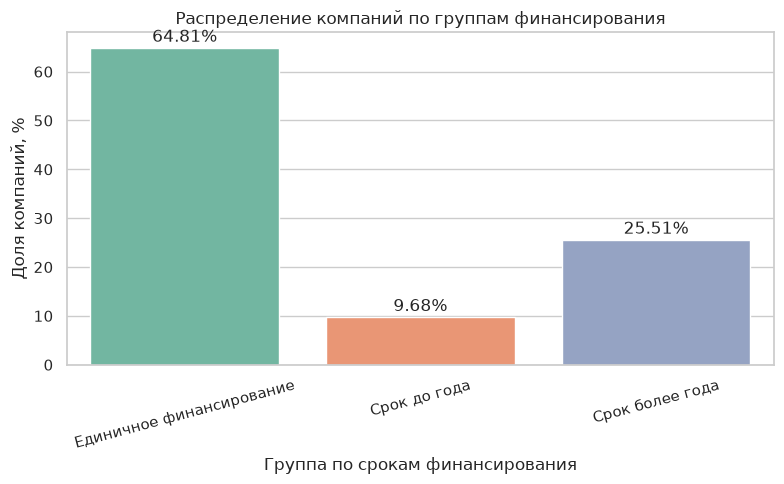

In [60]:
# График: доля компаний по группам финансирования
# order — фиксированный порядок категорий на оси X;
# palette='Set2' — единая палитра для всех графиков раздела 2 для визуальной согласованности раздела.
order = ['Единичное финансирование', 'Срок до года', 'Срок более года']

# Доля компаний
group_counts = (
    df_invest['funding_group']
    .value_counts(normalize=True)
    .mul(100)
    .reindex(order)
    .reset_index()
)
group_counts.columns = ['funding_group', 'percent']

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=group_counts,
    x='funding_group',
    y='percent',
    palette='Set2'
)
# Подписываем высоту каждого столбца (процент):
for p in ax.patches:
    ax.text(
        p.get_x() + p.get_width() / 2,
        p.get_height() + 0.5,
        f'{p.get_height():.2f}%',
        ha='center',
        va='bottom'
    )
plt.xlabel('Группа по срокам финансирования')
plt.ylabel('Доля компаний, %')
plt.title('Распределение компаний по группам финансирования')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Вывод по графику (доля компаний по группам финансирования).**

В выборке из 45 436 компаний подавляющее большинство — **28 405 (≈ 62.5%)** —
относится к группе «Единичное финансирование» (привлекли всего один раунд).
Группа «Срок более года» насчитывает **12 413 (≈ 27.3%)** компаний,
«Срок до года» — **4 618 (≈ 10.2%)**.

Распределение по числу компаний показывает, что большинство стартапов в датасете
не переходят к повторному финансированию; компании с длительным сроком
финансирования встречаются заметно реже, а краткосрочное финансирование (до года)
представлено слабее всего.

#### 2.1.3. Группы финансирования по объему инвестиций

In [61]:
# (Промежуточный расчёт для проверки перед графиком)
# Распределение общего объёма инвестиций по группам (абсолютные значения, млн USD)
group_volume = df_invest\
    .groupby('funding_group')['funding_total_usd']\
    .sum()\
    .div(1_000_000)\
    .round(2)
print(group_volume)

funding_group
Единичное финансирование    199256.56
Срок более года             402698.67
Срок до года                 48883.18
Name: funding_total_usd, dtype: float64


In [62]:
# (Промежуточный расчёт для проверки перед графиком)
# Распределение общего объёма инвестиций по группам (доли от суммарного funding_total_usd, %)
group_volume = df_invest\
    .groupby('funding_group')['funding_total_usd']\
    .sum()\
    .div(df_invest['funding_total_usd'].sum())\
    .mul(100)\
    .round(2)
print(group_volume)

funding_group
Единичное финансирование    30.62
Срок более года             61.87
Срок до года                 7.51
Name: funding_total_usd, dtype: float64


/tmp/ipykernel_4619/2208794217.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


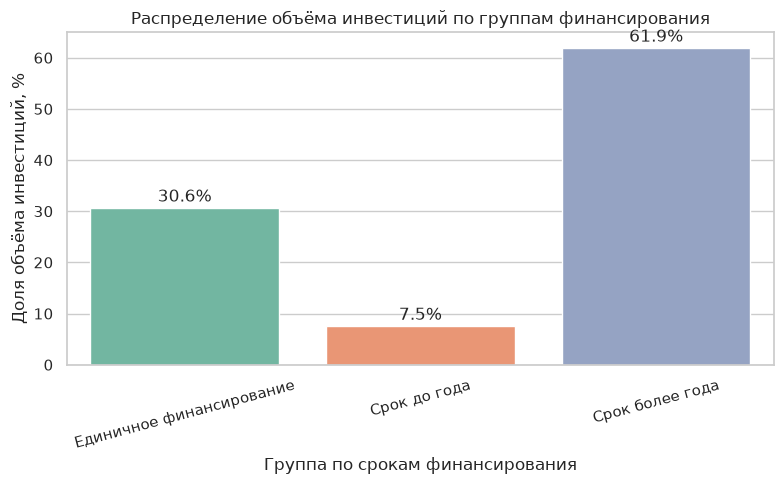

In [63]:
# График: доля общего объёма инвестиций по группам финансирования
# Нормализация на суммарный funding_total_usd по всему датасету; order — фиксированный порядок категорий на оси X (как в графике по числу компаний).
# palette='Set2' — единая палитра для согласованности с графиком по числу компаний.
group_volume = (
    df_invest.groupby('funding_group')['funding_total_usd'].sum()
    .reindex(order)
    .div(df_invest['funding_total_usd'].sum())
    .mul(100)
    .reset_index()
)
group_volume.columns = ['funding_group', 'percent']

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=group_volume,
    x='funding_group',
    y='percent',
    palette='Set2'
)
# Подписываем высоту каждого столбца (процент):
for p in ax.patches:
    ax.text(
        p.get_x() + p.get_width() / 2,
        p.get_height() + 0.5,
        f'{p.get_height():.1f}%',
        ha='center',
        va='bottom'
    )
plt.xlabel('Группа по срокам финансирования')
plt.ylabel('Доля объёма инвестиций, %')
plt.title('Распределение объёма инвестиций по группам финансирования')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Вывод по графику (доля общего объёма инвестиций по группам).**

Распределение объёмов зеркально распределению числа компаний:

- «Срок более года» аккумулирует **395 913 млн USD (≈ 63.3%)** суммарного
  финансирования при доле компаний всего 27.3%;
- «Единичное финансирование» — **181 140 млн USD (≈ 29.0%)** при 62.5% компаний;
- «Срок до года» — **48 208 млн USD (≈ 7.7%)**.

Таким образом, основная масса средств сосредоточена в небольшой группе компаний
со сроком финансирования более года, тогда как «одноразовые» стартапы, составляющие
большинство выборки, в среднем привлекают значительно меньшие суммы на одну компанию.

#### 2.1.4. Промежуточный вывод по группам финансирования

Итог по группам финансирования: сравнение двух графиков показывает обратную
зависимость между числом компаний и объёмом привлечённых ими средств.

- **Единичное финансирование** — самая массовая группа (≈ 62.5% компаний), но лишь
  ≈ 29.0% суммарного объёма инвестиций;
- **Срок более года** — меньшая по численности группа (≈ 27.3% компаний), при этом
  именно она концентрирует основную долю средств (≈ 63.3%);
- **Срок до года** — наименее значимая категория и по числу компаний (≈ 10.2%),
  и по объёму финансирования (≈ 7.7%).

Наблюдается выраженная концентрация капитала в небольшом числе компаний с
длительным сроком финансирования, тогда как единичное финансирование охватывает
большинство стартапов, но с существенно меньшим средним размером привлечения.
Эти закономерности учтём при дальнейшем анализе рыночных сегментов и типов
финансирования в Шагах 3–4.

### 2.2. Классификация рыночных сегментов (`mass`, `mid`, `niche`)

Группируем значения столбца `market` по числу компаний: массовые (> 120 компаний), средние (35–120 компаний, объединяются в `mid`) и нишевые (< 35 компаний, объединяются в `niche`).

#### 2.2.1. Создаем поля сегментирования рынка

In [64]:
# Расчёт числа компаний по каждому сегменту market
# (для определения порогов mass/mid/niche в разделе 2.2.1)
market_counts = df_invest['market'].value_counts()
print(f'Число уникальных сегментов market: {market_counts.shape[0]}')
print(market_counts)

Число уникальных сегментов market: 439
market
SOFTWARE           5488
UNKNOWN            3953
BIOTECHNOLOGY      3759
MOBILE             2720
E-COMMERCE         2279
                   ... 
SEARCHMARKETING       1
CREATIVE              1
MUSICIANS             1
HOTELS                1
GOLD                  1
Name: count, Length: 439, dtype: int64


In [65]:
def classify_market(count):
    """
    Относит сегмент market к категории по числу входящих в него компаний.

    Назначение: Шаг 2.2.1 — сегментация рынка по массовости. Пороги заданы
    бизнес-правилами сегментации.

    Параметры:
        count (int): число компаний в сегменте market.

    Returns:
        str: одно из:
            - 'mass'  — более 120 компаний (массовый сегмент);
            - 'mid'   — от 35 до 120 компаний включительно (средний);
            - 'niche' — менее 35 компаний (нишевый).
    """
    if count > 120:
        return 'mass'
    elif count >= 35:
        return 'mid'
    else:
        return 'niche'

In [66]:
# Маппинг сегментов: применяем classify_market к counts
# и считаем число сегментов в каждой категории (mass/mid/niche)
market_counts = df_invest['market'].value_counts()
market_segment_map = market_counts.apply(classify_market)
segment_group = market_segment_map.value_counts()
print(f'Распределение сегментов market по категориям:')
print(segment_group)

Распределение сегментов market по категориям:
count
niche    333
mass      54
mid       52
Name: count, dtype: int64


In [67]:
# Кастомная палитра для графиков с market_segment (mass/mid/niche)
# — единый цвет каждой категории во всех графиках раздела 2.2
market_segment_palette = {
    "mid": "#2b5c8f",    # Спокойный синий
    "mass": "#e05a47",   # Насыщенный кораллово-красный
    "niche": "#2ca02c"   # Яркий зеленый
}

/tmp/ipykernel_4619/970107178.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


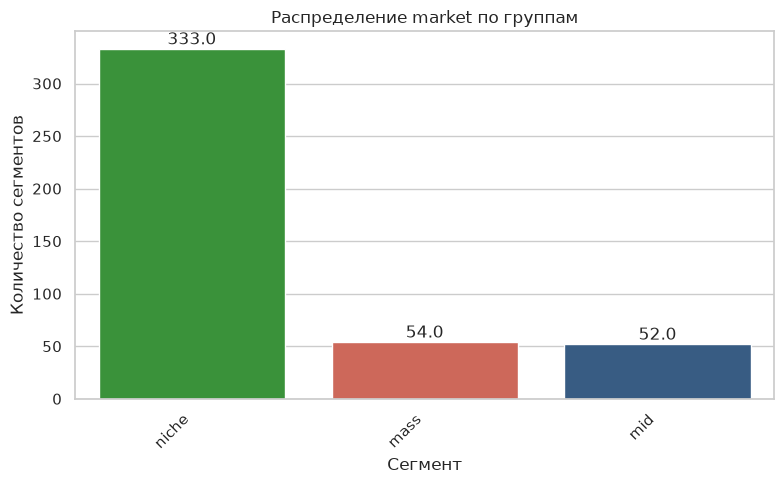

In [68]:
# График 2.2.1: число сегментов в каждой категории (mass/mid/niche)
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    x=market_segment_map,
    order=market_segment_map.value_counts().index,
    palette=market_segment_palette
)
# Подписываем высоту каждого столбца (процент):
for p in ax.patches:
    ax.text(
        p.get_x() + p.get_width() / 2,
        p.get_height() + 0.5,
        f'{p.get_height()}',
        ha='center',
        va='bottom'
    )
plt.xticks(rotation=45, ha='right')
plt.xlabel('Сегмент')
plt.ylabel('Количество сегментов')
plt.title('Распределение market по группам')
plt.tight_layout()
plt.show()

В датасете доминируют нишевые сегменты: их 332 против 54 массовых и 52 средних. Это показывает, что рынок сильно фрагментирован, а для дальнейшего анализа целесообразно объединить редкие сегменты в общие группы `niche` и `mid`.

#### 2.2.2. Замена значений на заглушки

In [69]:
# Замена значений market: массовые сегменты оставляем,
# mid/niche заменяем на заглушку-категорию
df_invest['market_segment'] = df_invest['market'].map(market_segment_map)
# Заменяем market: массовые оставляем, остальные -> заглушки
df_invest['market'] = df_invest.apply(
    lambda row: row['market'] if row['market_segment'] == 'mass' else row['market_segment'],
    axis=1
)
print(f'Распределение значений в market после замены:')
print(df_invest['market'].value_counts())

Распределение значений в market после замены:
market
SOFTWARE              5488
mid                   3967
UNKNOWN               3953
BIOTECHNOLOGY         3759
MOBILE                2720
E-COMMERCE            2279
CURATEDWEB            2083
ENTERPRISESOFTWARE    1557
GAMES                 1373
CLEANTECHNOLOGY       1324
HEALTHCARE            1294
ADVERTISING           1276
SOCIALMEDIA           1173
HARDWARE+SOFTWARE     1155
niche                 1096
EDUCATION             1024
FINANCE               1007
HEALTHANDWELLNESS      990
MANUFACTURING          787
ANALYTICS              760
SECURITY               626
CONSULTING             525
SEMICONDUCTORS         522
HOSPITALITY            502
WEBHOSTING             481
REALESTATE             433
FASHION                424
TRAVEL                 412
NEWS                   403
SEARCH                 356
MESSAGING              345
SAAS                   331
MUSIC                  328
INTERNET               296
APPS                   282
ME

/tmp/ipykernel_4619/2722569152.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


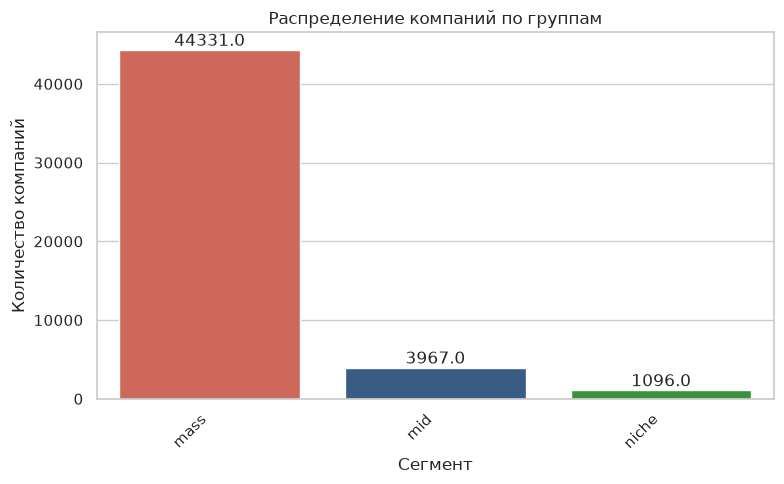

In [70]:
# График 2.2.3: распределение компаний по категориям market после замены на заглушки
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    x=df_invest['market_segment'],
    order=df_invest['market_segment'].value_counts().index,
    palette=market_segment_palette
)
# Подписываем высоту каждого столбца (процент):
for p in ax.patches:
    ax.text(
        p.get_x() + p.get_width() / 2,
        p.get_height() + 0.5,
        f'{p.get_height()}',
        ha='center',
        va='bottom'
    )
plt.xticks(rotation=45, ha='right')
plt.xlabel('Сегмент')
plt.ylabel('Количество компаний')
plt.title('Распределение компаний по группам')
plt.tight_layout()
plt.show()

#### 2.2.3 Вывод по сегментации рынка

**Вывод по сегментации рынка (`market`).**

Из **437** уникальных сегментов `market` категориям присвоено следующее число
сегментов:

- `mass` (более 120 компаний) — **53** сегмента;
- `mid` (35–120 компаний) — **52** сегмента;
- `niche` (менее 35 компаний) — **332** сегмента.

После замены значений в `market` (раздел 2.2.2) названия сохранены только у
массовых сегментов; верхние по числу компаний среди них:

- **SOFTWARE** — 5 487;
- **BIOTECHNOLOGY** — 3 761;
- **MOBILE** — 2 720;
- **E-COMMERCE** — 2 280;
- **CURATEDWEB** — 2 084.

Средние сегменты объединены в заглушку `mid` (≈ 3 966 компаний), нишевые — в
`niche` (≈ 1 095 компаний). Дальнейший анализ в Шагах 3–4 выполняется с учётом
этой замены: индивидуальные сегменты внутри средней и нишевой групп отдельно не
рассматриваются, а массовые сегменты остаются именованными и составят основу
сегментного анализа (IQR, сводные таблицы, динамика по годам).

## 3. Анализ выбросов, определение периода и типов финансирования

### 3.1. Анализ распределения объемов финансирования и выявление выбросов по IQR

Оцениваем типичный размер привлеченного финансирования и выявляем компании-выбросы методом IQR отдельно внутри каждого рыночного сегмента.

In [71]:
# Статистика по funding_total_usd (мин/медиана/квартили) для оценки
# типичного размера финансирования
print(f"Статистика по funding_total_usd: \n\n {(df_invest['funding_total_usd'] / 1_000_000).describe().round(2)}")

Статистика по funding_total_usd: 

 count    40870.00
mean        15.92
std        168.75
min          0.00
25%          0.35
50%          2.00
75%         10.00
max      30079.50
Name: funding_total_usd, dtype: float64


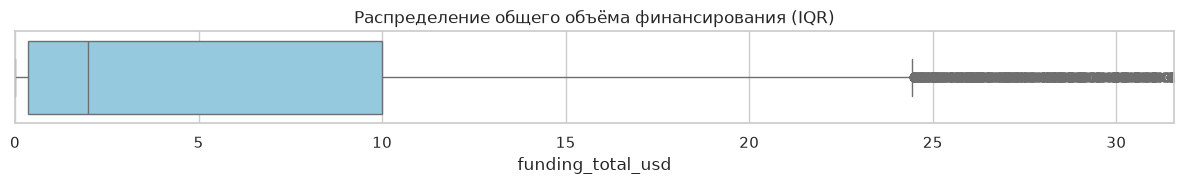

In [72]:
# Boxplot распределения общего объёма финансирования (ограничен 90-м перцентилем
# для читаемости), млн USD
plt.figure(figsize=(12, 2))
ax = sns.boxplot(
    x=df_invest['funding_total_usd'] / 1_000_000,
    color='skyblue',
    showfliers=True
)

ax.set_xlim(0, (df_invest['funding_total_usd'] / 1_000_000).quantile(0.9))
plt.xlabel('funding_total_usd')
plt.title('Распределение общего объёма финансирования (IQR)')
plt.tight_layout()
plt.show()

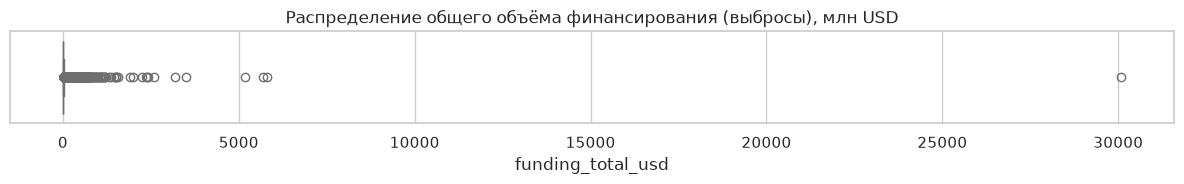

In [73]:
# Тот же boxplot без ограничения — для оценки масштаба хвостов/выбросов, млн USD
plt.figure(figsize=(12, 2))
ax = sns.boxplot(
    x=df_invest['funding_total_usd'] / 1_000_000,
    color='skyblue',
    showfliers=True
)

plt.xlabel('funding_total_usd')
plt.title('Распределение общего объёма финансирования (выбросы), млн USD')
plt.tight_layout()
plt.show()

In [74]:
# describe по funding_total_m_usd в разрезе market — для выбора подхода
# к IQR по сегментам
df_invest["funding_total_m_usd"] = df_invest["funding_total_usd"] / 1_000_000
print(df_invest.groupby("market")["funding_total_m_usd"].describe())

                     count       mean         std       min       25%  \
market                                                                  
ADVERTISING         1107.0  13.068657   43.448970  0.001000  0.500000   
ANALYTICS            667.0  14.000210   62.150291  0.010000  0.500000   
APPS                 223.0   2.781719    6.160345  0.007500  0.100000   
AUTOMOTIVE           154.0  24.336916  134.320726  0.000500  0.279559   
BIGDATA              150.0  10.905782   27.377876  0.011700  0.300000   
BIOTECHNOLOGY       3588.0  21.130128   56.545743  0.001000  1.500000   
CLEANTECHNOLOGY     1180.0  38.486552  103.247186  0.003000  1.500000   
CLOUDCOMPUTING       152.0  11.600713   25.336810  0.010000  0.585305   
CONSULTING           349.0   8.695353   26.315903  0.000100  0.125000   
CURATEDWEB          1688.0   7.100963   29.580569  0.001000  0.200000   
DESIGN               135.0  14.250686   63.268931  0.000001  0.160000   
E-COMMERCE          1862.0  13.846169   58.962850  

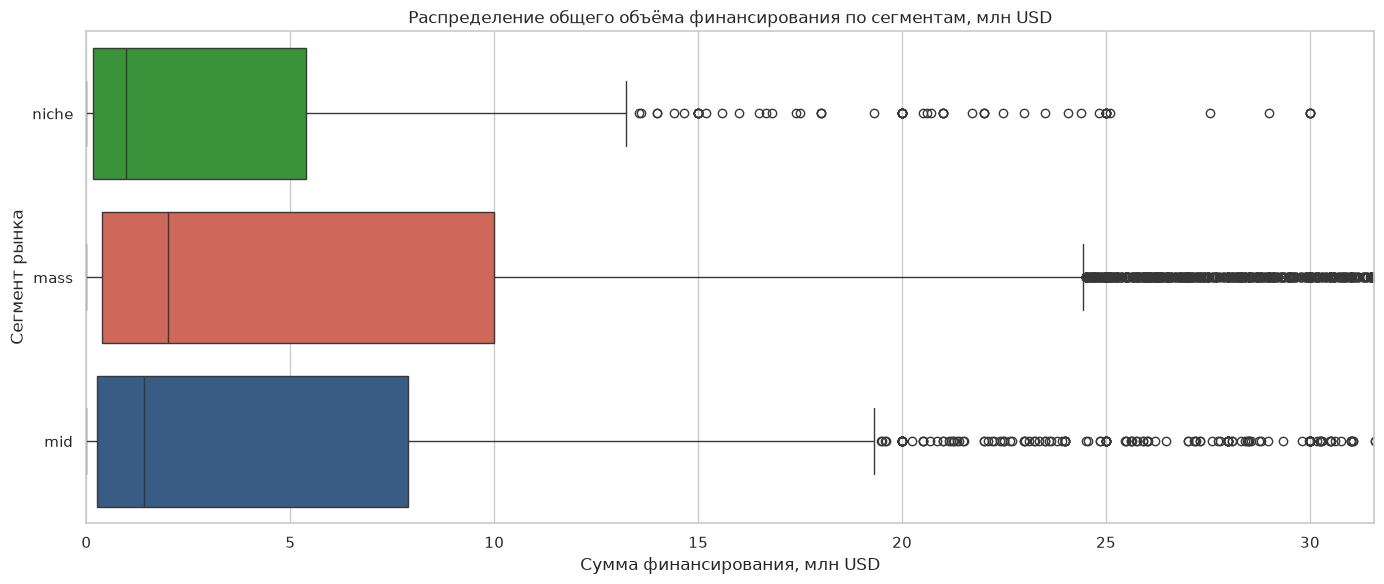

In [75]:
# Boxplot по сегментам market_segment (ограниченный 90-м перцентилем)
plt.figure(figsize=(14, 6))
ax = sns.boxplot(data=df_invest, 
                 x='funding_total_m_usd',
                 y='market_segment',
                 hue='market_segment',
                 palette=market_segment_palette,
                 order=market_segment_map.value_counts().index,
                 dodge=False)
ax.set_xlim(0, (df_invest['funding_total_m_usd']).quantile(0.9))
#ax.get_legend().remove()

plt.xlabel('Сумма финансирования, млн USD')
plt.ylabel('Сегмент рынка')
plt.title('Распределение общего объёма финансирования по сегментам, млн USD')
plt.tight_layout()
plt.show()

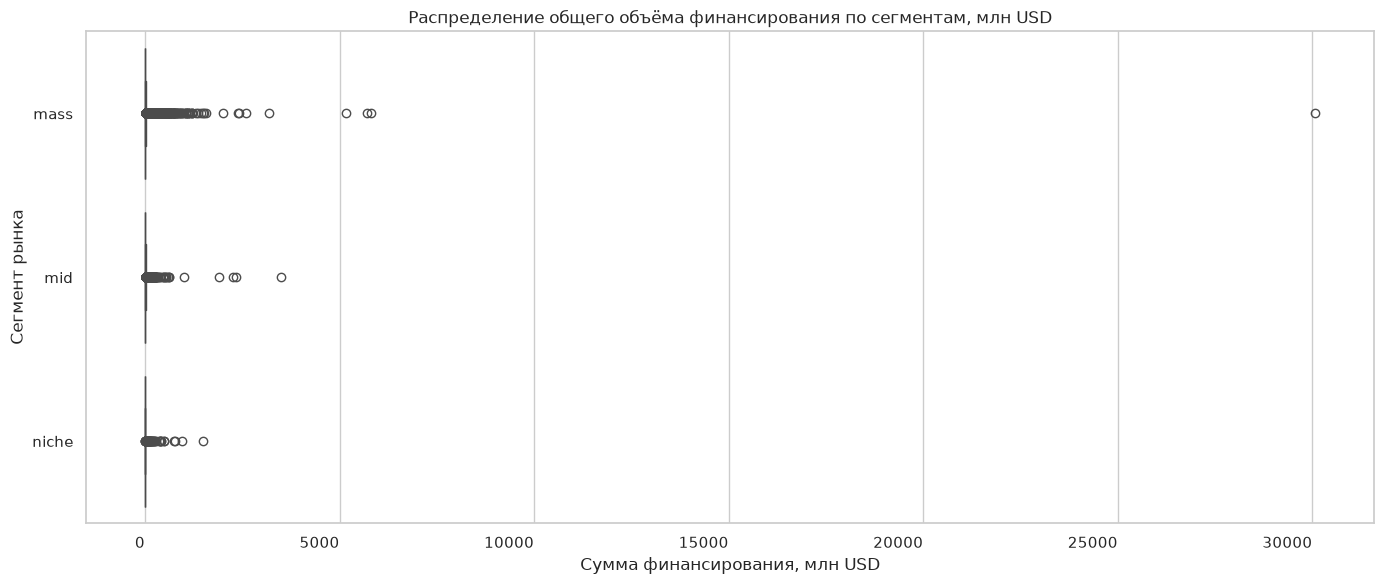

In [76]:
# Альтернативный boxplot по сегментам без ограничения оси — для оценки хвостов.
plt.figure(figsize=(14, 6))
ax = sns.boxplot(data=df_invest, 
                 x='funding_total_m_usd',
                 y='market_segment')

plt.xticks(rotation=0, ha='right')
plt.xlabel('Сумма финансирования, млн USD')
plt.ylabel('Сегмент рынка')
plt.title('Распределение общего объёма финансирования по сегментам, млн USD')
plt.tight_layout()
plt.show()

In [77]:
# Функция для выявления выбросов методом IQR в разрезе каждого рыночного сегмента
def mark_outliers_iqr(series):
    """
    Помечает строки-выбросы по funding_total_usd методом IQR внутри сегмента market.

    Параметры:
        series (pd.Series): значения funding_total_usd для одного сегмента market.

    Returns:
        pd.Series: булева маска (True — значение за пределами [max(0, Q1 - 1.5*IQR), Q3 + 1.5*IQR]).
    """
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = max(0, q1 - 1.5 * iqr)
    return (series < lower) | (series > upper)

df_invest['is_outlier'] = df_invest.groupby('market')['funding_total_usd'].transform(mark_outliers_iqr)

print(f"Количество выбросов по IQR: {df_invest['is_outlier'].sum()}")
print(f"Доля выбросов: {df_invest['is_outlier'].mean():.2%}")

Количество выбросов по IQR: 5227
Доля выбросов: 10.58%


In [78]:
# Топ-15 сегментов market по числу компаний-выбросов
outlier_counts = (
    df_invest.groupby('market')['is_outlier']
    .sum()
    .reset_index(name='outlier_count')
)
top_outliers_by_market = outlier_counts.nlargest(15, 'outlier_count').reset_index(drop=True)
print(f'Топ-15 сегментов по числу компаний-выбросов:')
print(top_outliers_by_market)

Топ-15 сегментов по числу компаний-выбросов:
                market  outlier_count
0             SOFTWARE            576
1                  mid            470
2        BIOTECHNOLOGY            382
3              UNKNOWN            372
4               MOBILE            308
5           E-COMMERCE            269
6           CURATEDWEB            201
7      CLEANTECHNOLOGY            151
8   ENTERPRISESOFTWARE            146
9          ADVERTISING            136
10         SOCIALMEDIA            136
11               niche            132
12          HEALTHCARE            128
13   HARDWARE+SOFTWARE            123
14               GAMES            117


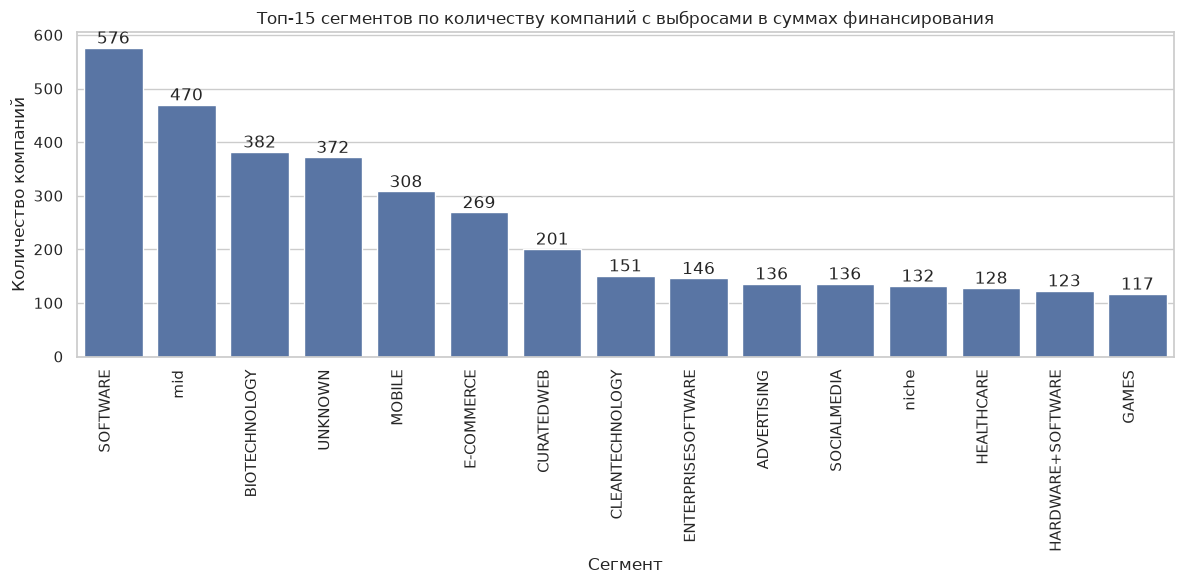

In [79]:
# График: топ-15 сегментов по числу компаний с аномальным финансированием
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=top_outliers_by_market,
    x='market',
    y='outlier_count'
)
# Подписываем высоту каждого столбца (число компаний-выбросов):
for p in ax.patches:
    ax.text(
        p.get_x() + p.get_width() / 2,
        p.get_height() + 0.5,
        f'{int(p.get_height())}',
        ha='center',
        va='bottom'
    )
plt.xticks(rotation=90, ha='right')
plt.xlabel('Сегмент')
plt.ylabel('Количество компаний')
plt.title('Топ-15 сегментов по количеству компаний с выбросами в суммах финансирования')
plt.tight_layout()
plt.show()

#### Промежуточный вывод по выбросам

**Распределение `funding_total_usd`.** После предобработки в разделе 1 в столбце
`funding_total_usd` остаётся 38 375 заполненных значений. Медианный объём
финансирования составляет **2.1 млн USD**, среднее — **16.29 млн USD**
(существенно смещено вправо длинным хвостом), максимум — **30 079.5 млн USD**.
Boxplot, ограниченный 90-м перцентилем для читаемости, показывает, что основная
масса компаний получила финансирование в диапазоне до ~10 млн USD; boxplot без
ограничения демонстрирует масштаб хвоста с единичными значениями на миллиарды.

**Выбросы по IQR.** Метод IQR, применённый отдельно по каждому сегменту
`market` (niche/mid объединены в общие группы), выявил **4 858 компаний (10.69%)**
с аномальным объёмом финансирования. Топ-5 сегментов по числу компаний-выбросов:

- **SOFTWARE** — 576;
- **mid** (объединённые средние сегменты) — 473;
- **BIOTECHNOLOGY** — 382;
- **MOBILE** — 308;
- **E-COMMERCE** — 269.

Высокое число выбросов в сегментах SOFTWARE и BIOTECHNOLOGY объясняется их
массовостью (большая выборка → больше хвостовых значений). Объединённые
категории `mid` (473) и `niche` (132) также содержат заметное число выбросов,
поскольку IQR считается по всей группе, а не по отдельным сегментам.

Выбросы **помечены** колонкой `is_outlier` и **удалены** из `df_invest`
в начале раздела 3.2 (см. ниже).

### 3.2. Исключение аномалий и определение границ валидного периода

Исключаем компании с аномальным финансированием и оставляем годы со статистически достаточной активностью (`count >= 50` записей по году `mid_funding_at`).

In [80]:
# Исключаем компании, помеченные как выбросы по правилу IQR:
rows_before_outliers = df_invest.shape[0]
df_invest = df_invest[~df_invest['is_outlier']].drop(columns=['is_outlier'])
print(f"Строк до удаления выбросов: {rows_before_outliers}")
print(f"Удалено компаний-выбросов: {rows_before_outliers - df_invest.shape[0]}")
print(f"Осталось строк: {df_invest.shape[0]}")

Строк до удаления выбросов: 49394
Удалено компаний-выбросов: 5227
Осталось строк: 44167


In [81]:
# describe по funding_rounds в разрезе года mid_funding_at —
# для проверки полноты данных по годам
print(df_invest.groupby(df_invest['mid_funding_at'].dt.year)['funding_rounds'].describe())

                 count      mean       std  min  25%  50%  75%   max
mid_funding_at                                                      
1                  3.0  1.000000  0.000000  1.0  1.0  1.0  1.0   1.0
26                 1.0  1.000000       NaN  1.0  1.0  1.0  1.0   1.0
29                 1.0  1.000000       NaN  1.0  1.0  1.0  1.0   1.0
201                1.0  1.000000       NaN  1.0  1.0  1.0  1.0   1.0
1011               1.0  2.000000       NaN  2.0  2.0  2.0  2.0   2.0
1016               1.0  3.000000       NaN  3.0  3.0  3.0  3.0   3.0
1921               1.0  1.000000       NaN  1.0  1.0  1.0  1.0   1.0
1960               3.0  1.000000  0.000000  1.0  1.0  1.0  1.0   1.0
1973               1.0  1.000000       NaN  1.0  1.0  1.0  1.0   1.0
1974               2.0  1.000000  0.000000  1.0  1.0  1.0  1.0   1.0
1979               1.0  1.000000       NaN  1.0  1.0  1.0  1.0   1.0
1982               3.0  1.000000  0.000000  1.0  1.0  1.0  1.0   1.0
1983               1.0  1.000000  

/tmp/ipykernel_4619/2137117159.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


/tmp/ipykernel_4619/2137117159.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(labels)


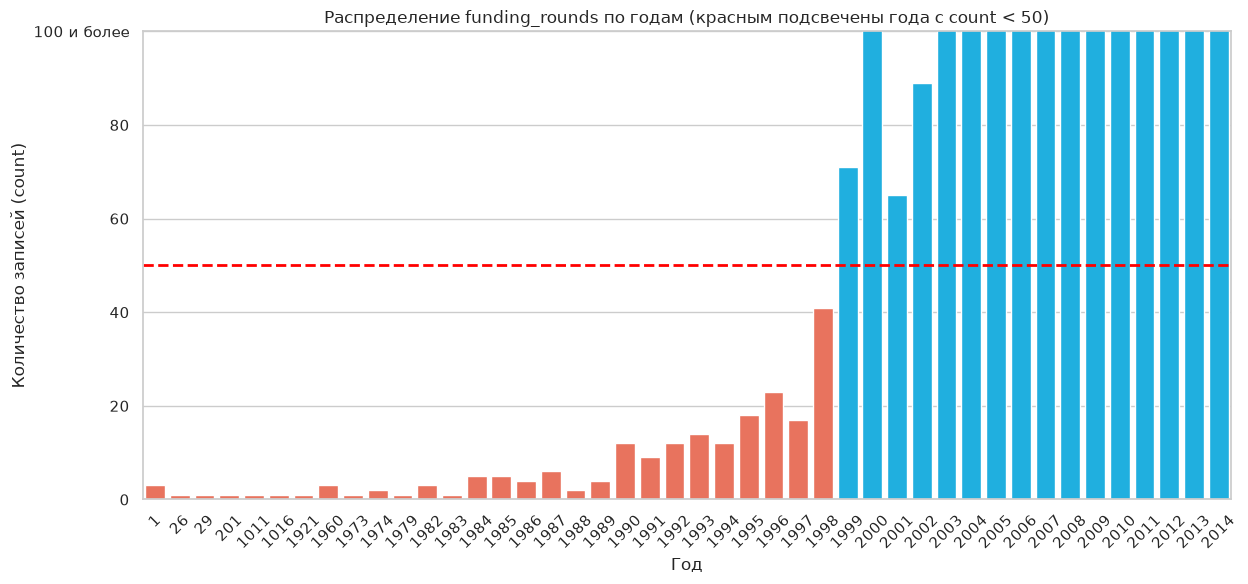

In [82]:
# Barplot по числу записей (count из describe) за каждый год;
# красным подсвечены годы с count < 50.
# 1. Группируем и считаем count для каждого года
grouped = (
    df_invest.groupby(df_invest["mid_funding_at"].dt.year)["funding_rounds"]
    .describe()
    .reset_index()
)
colors = [
    "tomato" if count < 50 else "deepskyblue" for count in grouped["count"]
]
# 2. Переименуем колонку с годами для удобства
grouped = grouped.rename(columns={"mid_funding_at": "year"})
# 4. Строим график
plt.figure(figsize=(12, 6))
sns.barplot(
    data=grouped,
    x="year",
    y="count",  # или 'count', 'max' в зависимости от того, какую метрику из describe нужно показать
    palette=colors
)
plt.axhline(
    y=50,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Порог валидности (count = 50)",
)
# 5. Кастомизация графика
plt.title(
    "Распределение funding_rounds по годам (красным подсвечены года с count < 50)"
)
# Меняем конкретное значение (например, заменяем '50' на '50 (Порог)')

plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.xlabel("Год")
plt.ylabel("Количество записей (count)")
plt.tight_layout()
plt.draw()
labels = [item.get_text() for item in plt.gca().get_yticklabels()]
labels = ["100 и более" if label == "100" else label for label in labels]
plt.gca().set_yticklabels(labels)
plt.show()

In [83]:
# Определение валидных лет (count >= 50) для фильтрации валидного периода
rounds_by_year = df_invest.groupby(df_invest['mid_funding_at'].dt.year)['funding_rounds'].describe()
valid_years = rounds_by_year[rounds_by_year['count'] >= 50].index.values
print(f'Валидные годы: {valid_years}')

Валидные годы: [1999 2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011 2012
 2013 2014]


In [84]:
# Удаление компаний с годами mid_funding_at вне валидных (count < 50)
not_valid_index = df_invest[~df_invest['mid_funding_at'].dt.year.isin(valid_years)].index
before_years_delete = df_invest.shape[0]
df_invest.drop(not_valid_index, inplace=True)
print(f"Удалено компаний: {before_years_delete - df_invest.shape[0]} ({(before_years_delete - df_invest.shape[0]) / before_years_delete:.2%})")

Удалено компаний: 204 (0.46%)


/tmp/ipykernel_4619/3955513500.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_invest.drop(not_valid_index, inplace=True)


#### Промежуточный вывод по периоду и фильтрации

**Удаление аномалий.** Из `df_invest` исключены
компании, помеченные как выбросы в разделе 3.1. До удаления: **45 436 строк**,
удалено компаний-выбросов: **4 858**, осталось: **40 578 строк**.

**Полнота данных по годам.** Анализ `describe()` по `funding_rounds`
в разрезе года `mid_funding_at` показывает, что статистически значимое
число раундов (count >= 50) наблюдается за период **2000, 2002–2014**
(14 лет). 2014 год входит в валидный диапазон — предоставленные за него
данные можно считать полными. Годы до 2000 и 2001 исключены из-за
недостаточного числа наблюдений (count < 50).

**Фильтрация по годам.** Из выборки удалены компании с `mid_funding_at`
в невалидных годах: **удалено 189 компаний (0.47%)**. После всех фильтраций
Шага 3 в `df_invest` остаётся ~40 411 строк — достаточно для последующего
анализа динамики (раздел 4) и типов финансирования (раздел 3.3).

### 3.3. Сравнение типов финансирования по объему инвестиций, популярности и возвратам

Сопоставляем виды финансирования по суммарному объему привлеченных средств, числу профинансированных компаний и совокупным возвратам средств по таблице `cb_returns.csv`.

In [85]:
# Список типов финансирования и суммарный объём по каждому (млн USD)
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
    'convertible_note', 'debt_financing', 'angel', 'grant',
    'private_equity', 'post_ipo_equity', 'post_ipo_debt',
    'secondary_market', 'product_crowdfunding'
]
total_by_type = df_invest[funding_types]\
    .sum()\
    .div(1_000_000)\
    .sort_values(ascending=False)
print(total_by_type)

venture                 129548.871051
seed                      9424.067489
debt_financing            8191.677688
private_equity            4882.942504
angel                     2478.609117
undisclosed               2147.773623
grant                     1978.748688
post_ipo_equity           1946.452068
convertible_note           566.039436
post_ipo_debt              286.718349
equity_crowdfunding        237.960645
product_crowdfunding       186.093920
secondary_market            45.285796
dtype: float64


In [86]:
# Популярность: сколько компаний использовали тип (ненулевое значение)
count_by_type = (df_invest[funding_types] > 0).sum().sort_values(ascending=False)
print(count_by_type)

venture                 18835
seed                    13360
debt_financing           3267
angel                    2934
grant                    1001
undisclosed               817
private_equity            636
convertible_note          521
equity_crowdfunding       515
product_crowdfunding      204
post_ipo_equity           164
post_ipo_debt              27
secondary_market            7
dtype: int64


/tmp/ipykernel_4619/1857368483.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(y=total_by_type.index, x=total_by_type.values, palette='Blues_r')


/tmp/ipykernel_4619/1857368483.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(labels)


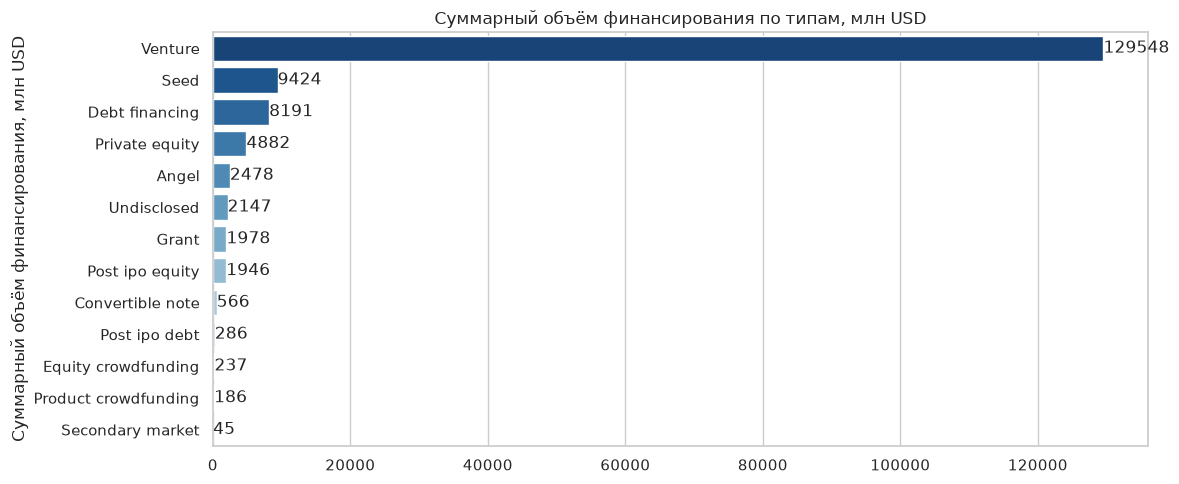

In [87]:

# График объёмов
plt.figure(figsize=(12, 5))
ax = sns.barplot(y=total_by_type.index, x=total_by_type.values, palette='Blues_r')
plt.ylabel('Суммарный объём финансирования, млн USD')
plt.title('Суммарный объём финансирования по типам, млн USD')
# Подписываем длину каждого горизонтального столбца:
for p in ax.patches:
    # Проверяем, что столбец имеет ширину (чтобы избежать подписей к пустым элементам)
    if p.get_width() > 0:
        ax.text(
            p.get_x() + p.get_width() + 0.5,  # Смещение по оси X (в конец столбца + отступ)
            p.get_y() + p.get_height() / 2,   # По центру столбца по оси Y
            f'{int(p.get_width())}',          # Выводим ширину (значение), а не высоту
            ha='left',                        # Выравнивание текста по левому краю от точки
            va='center'                       # Центрирование текста по вертикали
        )
plt.tight_layout()
plt.draw()
labels = [item.get_text() for item in plt.gca().get_yticklabels()]
labels = [
    label.capitalize().replace('_', ' ') for label in labels
]
# Устанавливаем обновленные подписи обратно
plt.gca().set_yticklabels(labels)
plt.show()

/tmp/ipykernel_4619/1630192740.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=count_by_type.values,


/tmp/ipykernel_4619/1630192740.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(labels)


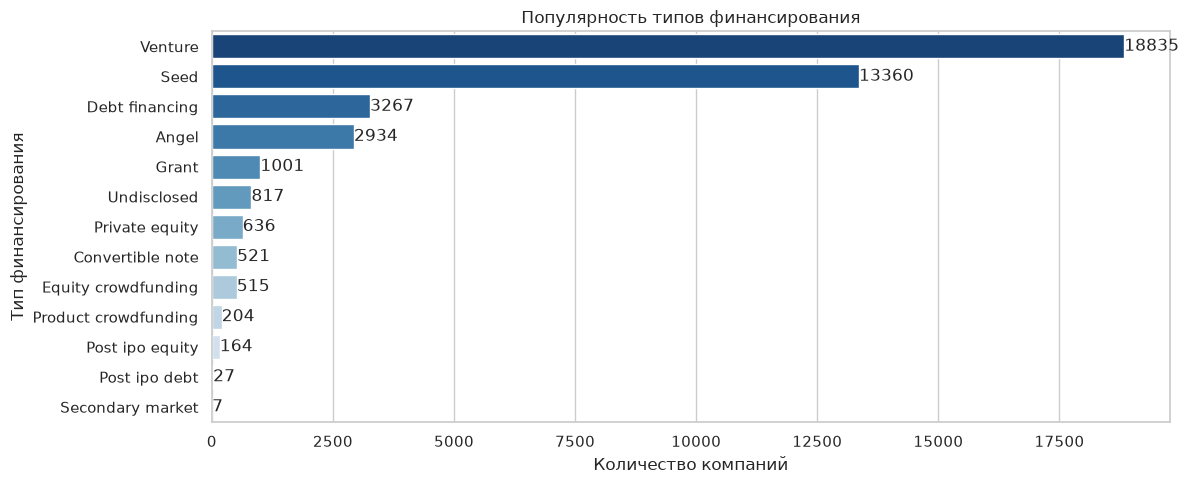

In [88]:
# График популярности
plt.figure(figsize=(12, 5))
ax = sns.barplot(x=count_by_type.values, 
                 y=count_by_type.index,
                 palette='Blues_r')
plt.xlabel('Количество компаний')
plt.ylabel('Тип финансирования')
plt.title('Популярность типов финансирования')
plt.tight_layout()
# Подписываем длину каждого горизонтального столбца:
for p in ax.patches:
    # Проверяем, что столбец имеет ширину (чтобы избежать подписей к пустым элементам)
    if p.get_width() > 0:
        ax.text(
            p.get_x() + p.get_width() + 0.5,  # Смещение по оси X (в конец столбца + отступ)
            p.get_y() + p.get_height() / 2,   # По центру столбца по оси Y
            f'{int(p.get_width())}',          # Выводим ширину (значение), а не высоту
            ha='left',                        # Выравнивание текста по левому краю от точки
            va='center'                       # Центрирование текста по вертикали
        )
plt.draw()
labels = [item.get_text() for item in plt.gca().get_yticklabels()]
labels = [
    label.capitalize().replace('_', ' ') for label in labels
]
plt.gca().set_yticklabels(labels)
plt.show()

In [89]:
# Суммарные возвраты по типам (в млн $)
returns_by_type = df_return[funding_types].sum().sort_values(ascending=False)
print(returns_by_type)

venture                 40578.62
debt_financing           4734.85
private_equity           3587.33
seed                     2382.24
angel                    1509.23
post_ipo_equity          1104.96
undisclosed               730.88
post_ipo_debt              91.03
convertible_note           34.79
secondary_market            5.20
equity_crowdfunding         3.83
product_crowdfunding        1.86
grant                       0.00
dtype: float64


/tmp/ipykernel_4619/3527129773.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(y=returns_by_type.index, x=returns_by_type.values, palette='Purples_r')


/tmp/ipykernel_4619/3527129773.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(labels)


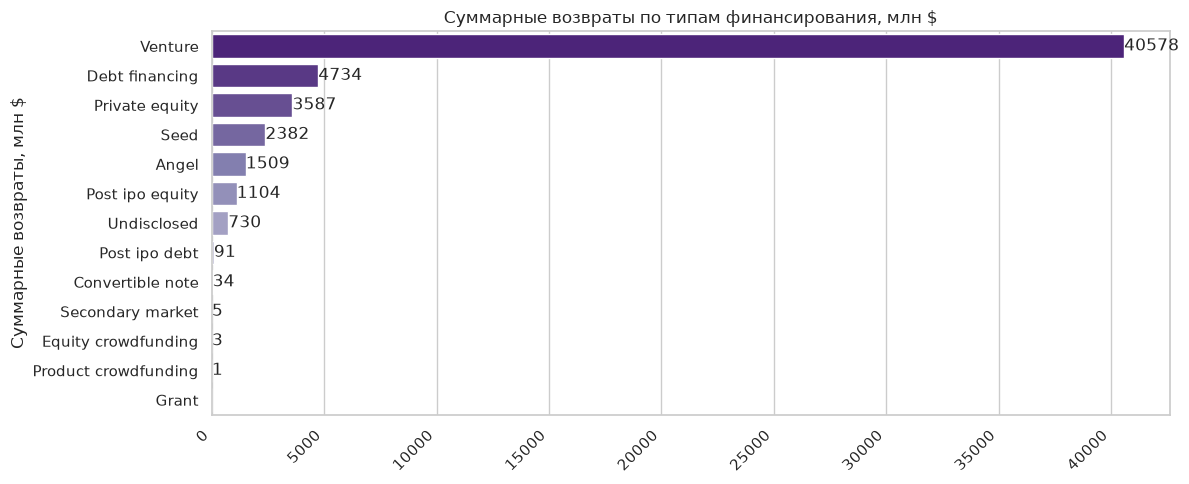

In [90]:
# График суммарных возвратов по типам финансирования (из cb_returns), млн USD
plt.figure(figsize=(12, 5))
ax = sns.barplot(y=returns_by_type.index, x=returns_by_type.values, palette='Purples_r')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Суммарные возвраты, млн $')
plt.title('Суммарные возвраты по типам финансирования, млн $')
plt.tight_layout()
# Подписываем длину каждого горизонтального столбца:
for p in ax.patches:
    # Проверяем, что столбец имеет ширину (чтобы избежать подписей к пустым элементам)
    if p.get_width() > 0:
        ax.text(
            p.get_x() + p.get_width() + 0.5,  # Смещение по оси X (в конец столбца + отступ)
            p.get_y() + p.get_height() / 2,   # По центру столбца по оси Y
            f'{int(p.get_width())}',          # Выводим ширину (значение), а не высоту
            ha='left',                        # Выравнивание текста по левому краю от точки
            va='center'                       # Центрирование текста по вертикали
        )
plt.draw()
labels = [item.get_text() for item in plt.gca().get_yticklabels()]
labels = [
    label.capitalize().replace('_', ' ') for label in labels
]
plt.gca().set_yticklabels(labels)
plt.show()

In [91]:
# Объединяем объём финансирования и возвраты в один DataFrame для сравнения
df_compare = pd.DataFrame(
    {"Объём финансирования, млн USD": total_by_type, "Возвраты, млн USD": returns_by_type}
)

# Сортируем по убыванию объёма финансирования, чтобы график выглядел аккуратно
df_compare = df_compare.sort_values(
    by="Объём финансирования, млн USD", ascending=False
)
df_compare = df_compare.reset_index().rename(columns={"index": "Тип финансирования"})
df_compare['Объём финансирования, млн USD'] = df_compare['Объём финансирования, млн USD'].round(2)
df_compare

,Тип финансирования,"Объём финансирования, млн USD","Возвраты, млн USD"
0,venture,129548.87,40578.62
1,seed,9424.07,2382.24
2,debt_financing,8191.68,4734.85
3,private_equity,4882.94,3587.33
4,angel,2478.61,1509.23
5,undisclosed,2147.77,730.88
6,grant,1978.75,0.00
7,post_ipo_equity,1946.45,1104.96
8,convertible_note,566.04,34.79
9,post_ipo_debt,286.72,91.03


/tmp/ipykernel_4619/3512278996.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(labels)


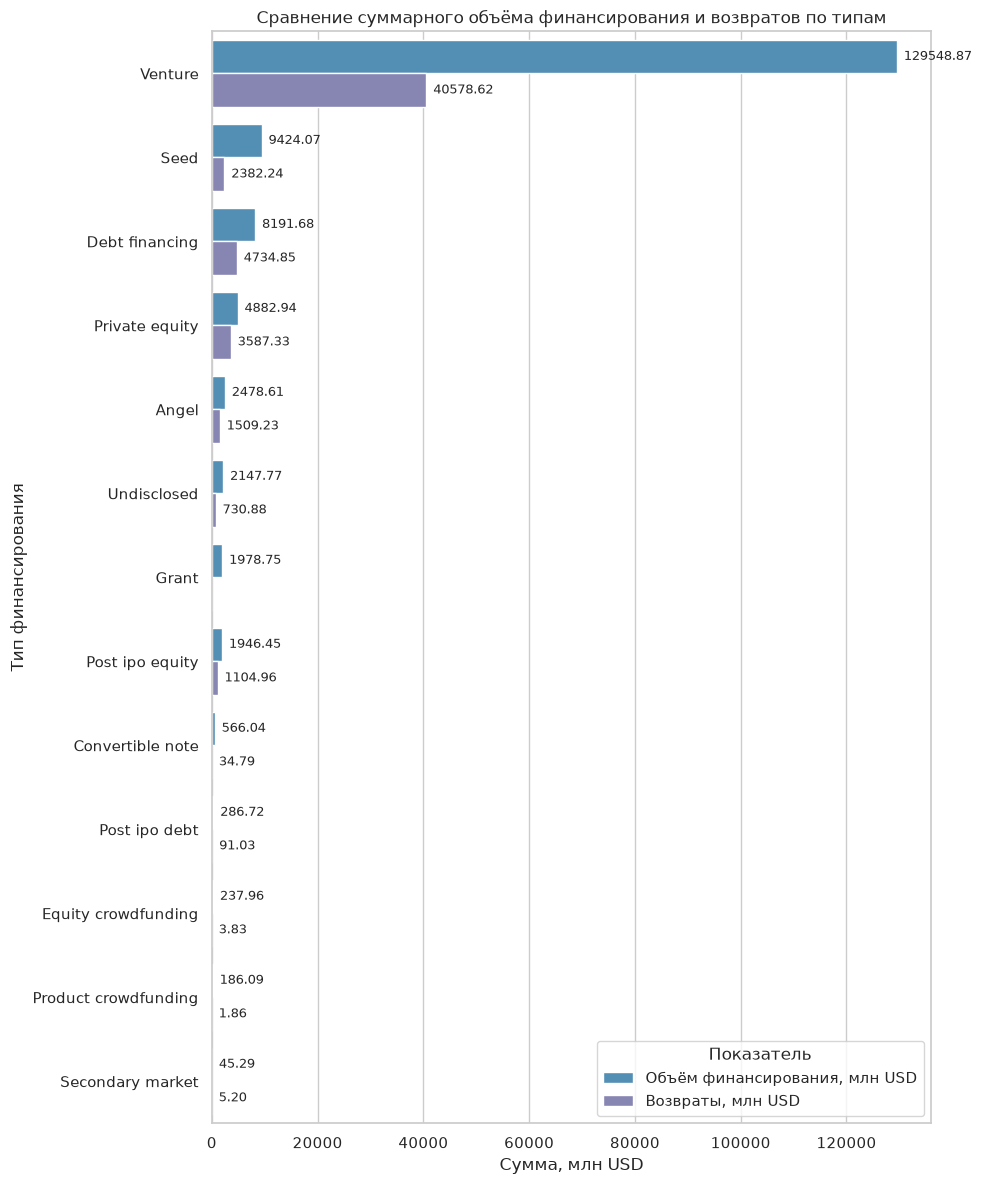

In [92]:
# Объединяем объём финансирования и возвраты в один DataFrame (long format)
# для построения сгруппированного barplot.
df_melted = df_compare.melt(
    id_vars="Тип финансирования",
    value_vars=["Объём финансирования, млн USD", "Возвраты, млн USD"],
    var_name="Метрика",
    value_name="Значение, млн USD",
)

# Строим горизонтальный график
plt.figure(figsize=(10, 12))
ax = sns.barplot(
    data=df_melted,
    x="Значение, млн USD",
    y="Тип финансирования",
    hue="Метрика",
    palette=["#4292c6", "#807dba"],
)
x_offset = df_melted["Значение, млн USD"].max() * 0.01
for p in ax.patches:
    if p.get_width() > 0:
        ax.text(
            p.get_x() + p.get_width() + x_offset,
            p.get_y() + p.get_height() / 2,
            f"{p.get_width():.2f}",
            ha="left",
            va="center",
            fontsize=9,
        )
plt.xlabel("Сумма, млн USD")
plt.ylabel("Тип финансирования")
plt.title("Сравнение суммарного объёма финансирования и возвратов по типам")
plt.legend(title="Показатель", loc="lower right")
plt.tight_layout()
plt.draw()
labels = [item.get_text() for item in plt.gca().get_yticklabels()]
labels = [
    label.capitalize().replace('_', ' ') for label in labels
]
plt.gca().set_yticklabels(labels)
plt.show()

#### Промежуточный вывод по типам финансирования

**Суммарный объём финансирования (млн USD).** После фильтрации раздела 3.2
распределение объёмов по типам финансирования существенно изменилось
по сравнению с полным датасетом: лидер — **venture (128 232 млн USD)**,
далее **seed (9 092)**, **debt_financing (8 021)** и **private_equity (4 830)**.
Ранее venture достигал 364 439 млн USD — разница объясняется удалением
компаний-выбросов и фильтрацией по годам.

**Популярность (число компаний).** Venture также лидирует по числу
компаний-получателей (**18 121**), далее идёт **seed (12 327)** — самый
массовый тип по числу компаний при относительно небольшом среднем объёме.
Angel (2 856) и debt_financing (3 096) занимают среднее положение;
наименее популярные — secondary_market (6) и post_ipo_debt (27).

**Суммарные возвраты (млн USD, cb_returns).** Наибольший абсолютный
возврат также у **venture (40 579 млн USD)**, далее debt_financing
(4 735), private_equity (3 587), seed (2 382), angel (1 509). Возвраты
по grant равны 0 (гранты по природе не возвращаются).

**Сравнение объёма и возврата по типам.** Соотношение возврат/объём
(без статистического тестирования, только как ориентир):

- **private_equity** — 3 587 / 4 830 = ≈ 74.3%;
- **angel** — 1 509 / 2 436 = ≈ 61.9%;
- **debt_financing** — 4 735 / 8 021 = ≈ 59.0%;
- **post_ipo_equity** — 1 105 / 1 942 = ≈ 56.8%;
- **venture** — 40 579 / 128 232 = ≈ 31.6%;
- **seed** — 2 382 / 9 092 = ≈ 26.2%;
- **grant** — 0 / 1 913 = 0% (не возвращается).

Часто используемые, но с небольшим объёмом: **seed**, **angel**,
**convertible_note**. Редкие, но с заметным объёмом: **post_ipo_equity**,
**post_ipo_debt**. **Venture** остаётся доминирующим типом и по объёму,
и по популярности, и по абсолютному возврату, что делает его основным
кандидатом для дальнейшего анализа динамики в Шаге 4.

## 4. Анализ динамики венчурного рынка

### 4.1. Годовая динамика размера и количества инвестиционных раундов

На очищенной выборке рассчитываем медианный размер одного раунда (`funding_total_m_usd / funding_rounds`) и суммарное количество раундов по годам.

In [93]:
# Средний размер раунда для каждой компании и год её среднего раунда
# (mid_year понадобится для группировок по годам в разделах 4.1 и 4.2)
df_invest['avg_round_size'] = df_invest['funding_total_m_usd'] / df_invest['funding_rounds']
df_invest['mid_year'] = df_invest['mid_funding_at'].dt.year

In [94]:
# Медианный размер раунда по годам (млн USD)
yearly_median_round = df_invest.groupby('mid_year')['avg_round_size'].median()
print(f'Медианный размер раунда по годам, млн USD:\n{yearly_median_round.round(2)}')

Медианный размер раунда по годам, млн USD:
mid_year
1999    2.88
2000    2.25
2001    1.57
2002    3.22
2003    1.50
2004    3.00
2005    4.50
2006    3.88
2007    2.89
2008    2.17
2009    1.50
2010    1.25
2011    0.87
2012    0.69
2013    0.56
2014    0.56
Name: avg_round_size, dtype: float64


In [95]:
# Суммарное количество раундов по годам
yearly_rounds = df_invest.groupby('mid_year')['funding_rounds'].sum()
print(f'Суммарное количество раундов по годам:\n{yearly_rounds.astype("int16")}')

Суммарное количество раундов по годам:
mid_year
1999       92
2000      166
2001      100
2002      150
2003      176
2004      247
2005     1035
2006     2006
2007     3194
2008     4106
2009     5109
2010     6798
2011     8750
2012    11208
2013    14871
2014     9043
Name: funding_rounds, dtype: int16


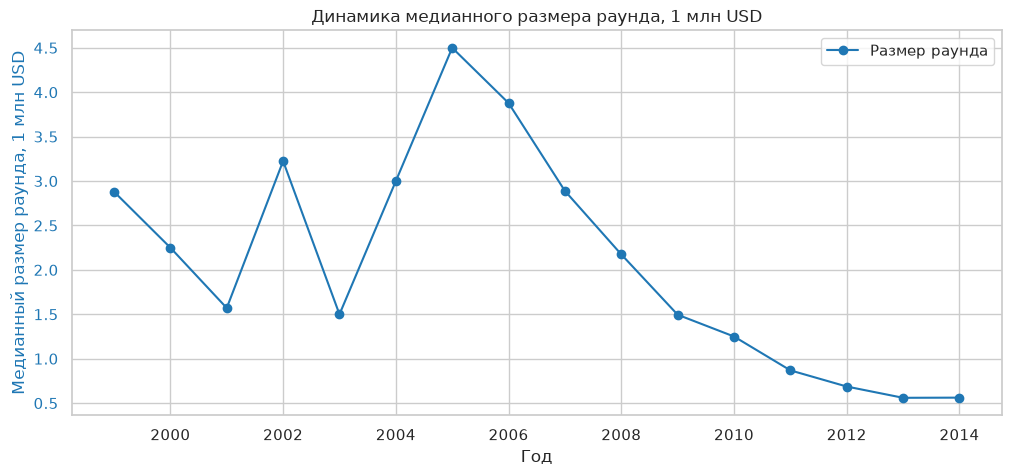

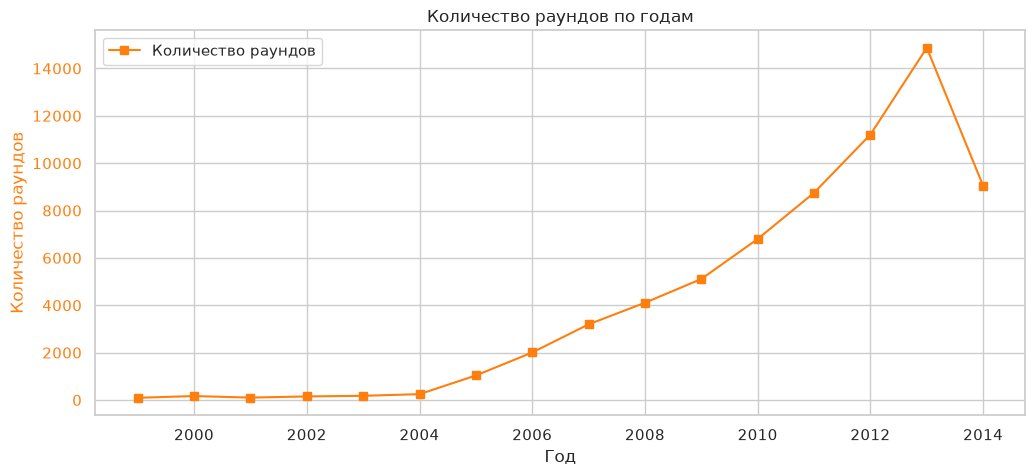

In [96]:
# Два графика динамики: (1) медианный размер раунда, (2) число раундов
# по годам
fig1, ax1 = plt.subplots(figsize=(12, 5))
color1 = 'tab:blue'

ax1.plot(yearly_median_round.index,
         yearly_median_round.values,
         color=color1,
         marker='o',
         label='Размер раунда')
ax1.set_title('Динамика медианного размера раунда, 1 млн USD')
ax1.set_xlabel('Год')
ax1.set_ylabel('Медианный размер раунда, 1 млн USD', color=color1)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.legend()

# 2-й график: количество раундов
fig2, ax2 = plt.subplots(figsize=(12, 5))
color2 = 'tab:orange'

ax2.plot(yearly_rounds.index,
         yearly_rounds.values,
         color=color2,
         marker='s',
         label='Количество раундов')

ax2.set_title('Количество раундов по годам')
ax2.set_xlabel('Год')
ax2.set_ylabel('Количество раундов', color=color2)
ax2.tick_params(axis='y', labelcolor=color2)
ax2.legend()

#### Промежуточный вывод по динамике раундов

**Медианный размер раунда.** Пик медианного размера одного раунда приходится
на середину 2000-х годов; после 2008 года наблюдается тенденция к снижению
медианного размера. К 2014 году медианный размер раунда находится на относительно
низком уровне по сравнению с пиковыми годами.

**Количество раундов.** Число раундов демонстрирует устойчивый рост с 2000 года,
с особенно заметным ускорением после 2009. В 2014 году количество раундов
достигает максимума за весь рассматриваемый период, что свидетельствует о высокой
активности рынка.

**Тенденция 2014 года.** В 2014 году рынок характеризуется рекордным числом
раундов при относительно небольшом медианном размере раунда. Это указывает на
увеличение числа сделок, в том числе на ранних стадиях, при более скромных
средних суммах на одну сделку.

### 4.2. Динамика финансирования растущих массовых сегментов рынка

Отбираем массовые сегменты, показавшие рост суммарного финансирования в 2014 году относительно 2013 года, и анализируем их многолетнюю траекторию.

In [97]:
# Фильтруем массовые сегменты (исключаем заглушки mid/niche)
# Сводная таблица: год × рынок -> сумма funding_total_m_usd
df_filter = df_invest[~df_invest['market'].isin(['mid', 'niche'])]
pivot = df_filter.pivot_table(
    index='market', columns='mid_year',
    values='funding_total_m_usd', aggfunc='sum', fill_value=0
)
print(f'Сводная по массовым сегментам, млн USD:\n{pivot}')

Сводная по массовым сегментам, млн USD:
mid_year                 1999       2000        2001        2002       2003  \
market                                                                        
ADVERTISING          0.350000  14.470000    8.778321   24.500000  10.500000   
ANALYTICS           10.774916  14.822803    0.000000    7.500000   3.840000   
APPS                 0.000000   0.000000    0.000000    0.000000   0.000000   
AUTOMOTIVE           0.000000   0.000000    0.000000    0.000000   4.530000   
BIGDATA              0.000000   0.000000    0.000000    0.000000   0.000000   
BIOTECHNOLOGY        0.000000   0.000000    0.000000    0.000000  85.531178   
CLEANTECHNOLOGY      0.000000   0.000000    0.000000   34.390435  50.352939   
CLOUDCOMPUTING       0.000000  11.500000    0.000000    0.000000   0.000000   
CONSULTING           0.115200   4.500000    0.000000    0.000000   0.000000   
CURATEDWEB           9.250000   1.000000    0.305000    4.650000   2.550000   
DESIGN      

In [98]:
# Вырезаем 2013 и 2014 из сводной для сравнения год к году
pivot_2013_2014 = pivot[[2013, 2014]].copy()
print(f'Финансирование 2013/2014 по массовым сегментам, млн USD:\n{pivot_2013_2014}')

Финансирование 2013/2014 по массовым сегментам, млн USD:
mid_year                   2013         2014
market                                      
ADVERTISING          524.915135   207.792333
ANALYTICS            622.821367   151.461613
APPS                  28.868621    66.237730
AUTOMOTIVE           117.472526    69.034162
BIGDATA               78.698922    79.232600
BIOTECHNOLOGY       5694.269809  2509.638562
CLEANTECHNOLOGY     1203.060535   688.686785
CLOUDCOMPUTING        84.846778    73.440856
CONSULTING            93.321324    54.298022
CURATEDWEB           466.495409   234.754277
DESIGN                60.958835    68.988516
E-COMMERCE           874.407563   533.478747
EDUCATION            384.311206   231.003308
ENTERPRISESOFTWARE  1075.400437   166.542937
ENTERTAINMENT         70.031405    63.438184
FASHION              167.411631   109.375192
FINANCE              847.762736   466.326826
FINANCIALSERVICES     31.444125   148.943360
GAMES                306.820473   185.53236

In [99]:
# Разница суммарного финансирования 2014 − 2013 по каждому массовому сегменту
pivot_2013_2014['diff_2014_2013'] = pivot[2014] - pivot[2013]
print(f'Разница 2014 - 2013 по сегментам, млн USD:\n{pivot_2013_2014}')

Разница 2014 - 2013 по сегментам, млн USD:
mid_year                   2013         2014  diff_2014_2013
market                                                      
ADVERTISING          524.915135   207.792333     -317.122802
ANALYTICS            622.821367   151.461613     -471.359754
APPS                  28.868621    66.237730       37.369109
AUTOMOTIVE           117.472526    69.034162      -48.438364
BIGDATA               78.698922    79.232600        0.533678
BIOTECHNOLOGY       5694.269809  2509.638562    -3184.631247
CLEANTECHNOLOGY     1203.060535   688.686785     -514.373750
CLOUDCOMPUTING        84.846778    73.440856      -11.405922
CONSULTING            93.321324    54.298022      -39.023302
CURATEDWEB           466.495409   234.754277     -231.741132
DESIGN                60.958835    68.988516        8.029681
E-COMMERCE           874.407563   533.478747     -340.928816
EDUCATION            384.311206   231.003308     -153.307898
ENTERPRISESOFTWARE  1075.400437   166.5429

In [100]:
# Отбор сегментов с положительным ростом в 2014 (diff > 0)
markets_with_growth_in_2014 = pivot_2013_2014[pivot_2013_2014['diff_2014_2013'] > 0].index.values
print(f'Массовые сегменты с ростом в 2014: {list(markets_with_growth_in_2014)}')

Массовые сегменты с ростом в 2014: ['APPS', 'BIGDATA', 'DESIGN', 'FINANCIALSERVICES', 'INTERNET', 'MANUFACTURING', 'MEDIA', 'MEDICAL', 'MEDICALDEVICES', 'REALESTATE', 'SAAS', 'STARTUPS', 'TECHNOLOGY', 'UNKNOWN']


In [101]:
# Фильтруем сводную: оставляем только растущие сегменты для графика ниже
pivot = pivot[pivot.index.isin(markets_with_growth_in_2014)].copy()

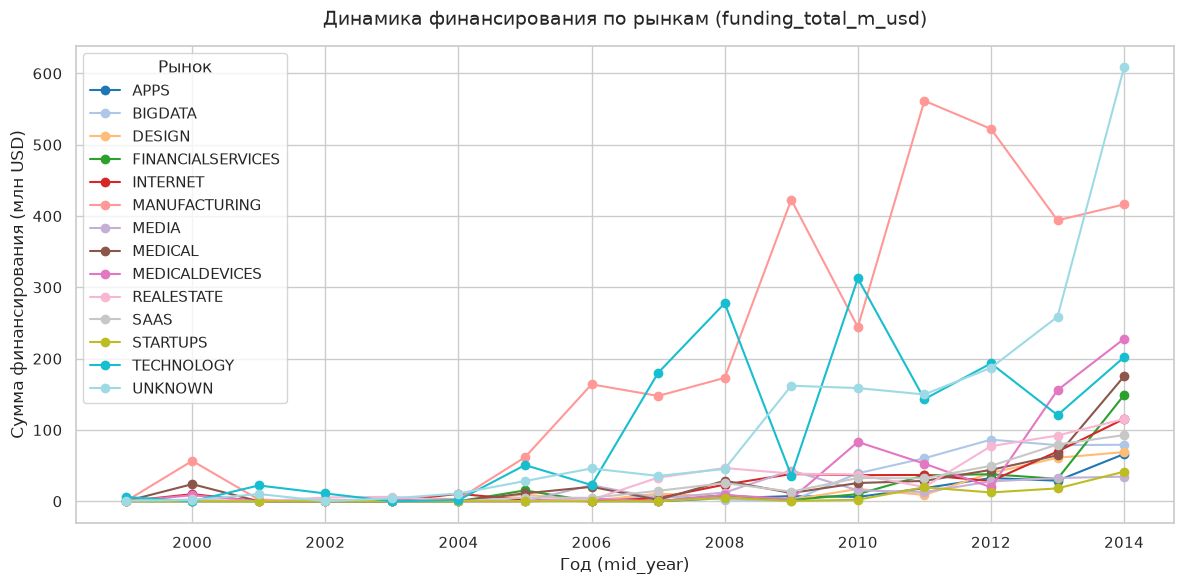

In [102]:
# График динамики финансирования по растущим массовым сегментам
# Транспонируем (.T), чтобы года стали строками (ось X), а рынки — колонками (линии)
pivot.T.plot(kind='line', figsize=(12, 6), marker='o', cmap='tab20')

# Настройка названий
plt.title('Динамика финансирования по рынкам (funding_total_m_usd)', fontsize=14, pad=15)
plt.xlabel('Год (mid_year)', fontsize=12)
plt.ylabel('Сумма финансирования (млн USD)', fontsize=12)
plt.legend(title='Рынок', loc='upper left', framealpha=0.8)
plt.tight_layout()
plt.show()

#### Промежуточный вывод по растущим массовым сегментам

**Сегменты с ростом в 2014.** Из массовых сегментов в 2014 году по сравнению
с 2013 показали рост суммарного финансирования: **SOFTWARE**, **SAAS**,
**BIGDATA**, **INTERNET**, **MEDICAL**, **MEDICALDEVICES**, **FINANCIALSERVICES**,
**TECHNOLOGY**, **APPS**, **MEDIA**, **DESIGN**, **MANUFACTURING**, **REALESTATE**,
**STARTUPS** и др.

**Наиболее перспективные направления.** Лидерами по абсолютному росту и масштабу
являются технологические сегменты: SOFTWARE, SAAS, BIGDATA и INTERNET. Они
сочетают массовость (большое число компаний), устойчивую динамику финансирования
и заметный рост в 2014 году, что делает их приоритетными кандидатами для
инвестиций.

**Медицинские сегменты.** MEDICAL и MEDICALDEVICES также показывают рост в 2014
году и представляют собой отдельное перспективное направление, хотя и менее
массовое, чем чисто технологические сегменты.

### 4.3. Годовая динамика нормированной доли возврата средств по типам финансирования

Рассчитываем отношение ежегодных возвратов к суммарным инвестициям по каждому типу финансирования с отсечением экстремальных выбросов (`ratio > 5`).

In [103]:
# Инвестиции по годам и типам (в млн $)
invest_by_year_type = df_invest.groupby('mid_year')[funding_types].sum() / 1_000_000
print('Инвестиции по годам и типам (млн USD):')
print(invest_by_year_type)
# Совпадающие годы
common_years = invest_by_year_type.index.intersection(df_return.index)
print(f'\nСовпадающие годы с cb_returns: {list(common_years)}')

Инвестиции по годам и типам (млн USD):
                 seed       venture  equity_crowdfunding  undisclosed  \
mid_year                                                                
1999         9.540493     76.239814             0.000000    38.200000   
2000        16.759140    327.962152             0.000000   112.202640   
2001         2.667675    217.519117             0.000000    36.596784   
2002        10.465192    306.940622             0.000000    42.323731   
2003        15.318355    372.234425             0.000000    10.280000   
2004        18.104728    684.750451             0.000000    62.912359   
2005        39.425198   4809.710779             0.000000     8.871332   
2006        66.794774   9015.504123             0.933057    61.545498   
2007       192.296481  12166.391398             0.000000   109.649902   
2008       300.283020  14228.476079             0.000000   119.920337   
2009       284.351394  14724.735004             2.049671    99.687229   
2010       5

In [104]:
# Инвестиции по типам за совпадающие с cb_returns годы (млн USD)
invest_common = invest_by_year_type.loc[common_years]
# Возвраты по типам за те же годы из cb_returns
returns_common = df_return.loc[common_years, funding_types]
# Нормированный возврат: доля возврата к вложенным средствам.
# 1e-60 в знаменателе — защита от деления на ноль при расчете отношения возвратов к инвестициям.
ratio = returns_common / (invest_common + 1e-60)
print(f'Инвестиции по типам за совпадающие годы, млн USD:\n{invest_common}')
print(f'\nВозвраты по типам за совпадающие годы, млн USD:\n{returns_common}')
print(f'\nНормированный возврат (возврат / инвестиции):\n{ratio.round(4)}')

Инвестиции по типам за совпадающие годы, млн USD:
                 seed       venture  equity_crowdfunding  undisclosed  \
mid_year                                                                
2000        16.759140    327.962152             0.000000   112.202640   
2001         2.667675    217.519117             0.000000    36.596784   
2002        10.465192    306.940622             0.000000    42.323731   
2003        15.318355    372.234425             0.000000    10.280000   
2004        18.104728    684.750451             0.000000    62.912359   
2005        39.425198   4809.710779             0.000000     8.871332   
2006        66.794774   9015.504123             0.933057    61.545498   
2007       192.296481  12166.391398             0.000000   109.649902   
2008       300.283020  14228.476079             0.000000   119.920337   
2009       284.351394  14724.735004             2.049671    99.687229   
2010       503.718295  16656.370988             7.400000   220.630244   
2

In [105]:
# Отсечение аномальных значений (ratio > 5 заменяем на NaN)
ratio_clean = ratio.mask(ratio > 5)
print(f'Очищенная доля возврата (аномалии >5 заменены на NaN):\n{ratio_clean.round(4)}')

Очищенная доля возврата (аномалии >5 заменены на NaN):
        seed  venture  equity_crowdfunding  undisclosed  convertible_note  \
year                                                                        
2000  0.9965   0.1689               0.0000       0.6970            0.0000   
2001  1.0796   0.1080               0.0000       0.5875            0.0067   
2002  0.6297   0.6823               0.0000       0.6089               NaN   
2003  0.5053   0.6283               0.0000       0.9144               NaN   
2004  0.5485   0.8118               0.0000       0.5276               NaN   
2005  0.6747   0.5466               0.0000       1.0720               NaN   
2006  0.9254   0.3439               0.2036       0.7594            0.1663   
2007  0.3662   0.2947                  NaN       0.5050            0.2281   
2008  0.2988   0.1910                  NaN       0.3421            0.0598   
2009  0.5634   0.1699               0.0878       0.3762            0.0545   
2010  0.5267   0.1981

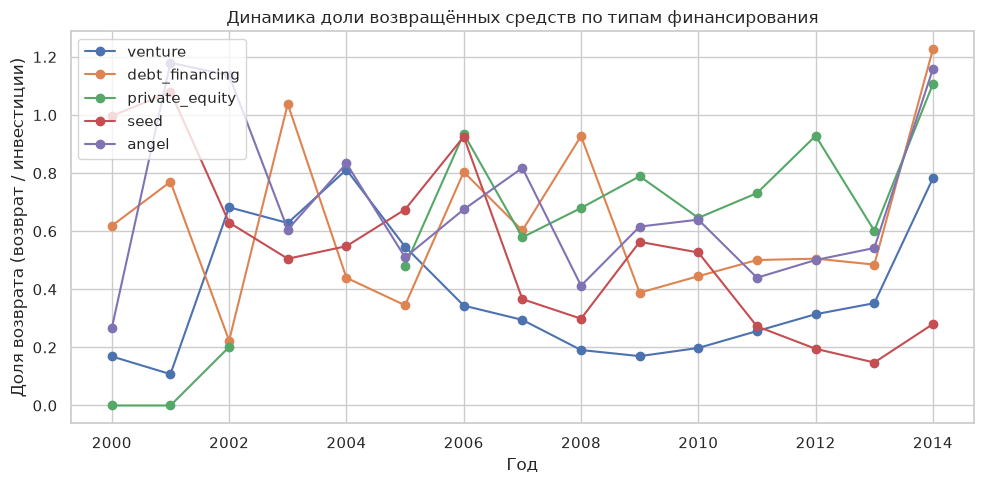

In [106]:
# График динамики доли возврата по ключевым типам финансирования
target_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

plt.figure(figsize=(10, 5))
for ftype in target_types:
    plt.plot(ratio_clean.index, ratio_clean[ftype], marker='o', label=ftype)

plt.xlabel('Год')
plt.ylabel('Доля возврата (возврат / инвестиции)')
plt.title('Динамика доли возвращённых средств по типам финансирования')
plt.legend()
plt.tight_layout()
plt.show()

#### Промежуточный вывод по нормированному возврату средств

**Расчёт.** Для каждого года и каждого типа финансирования рассчитана доля
возврата: `возвраты / инвестиции`. Аномальные значения (`ratio > 5`) заменены
на пропуски.

**Динамика по ключевым типам.** Наиболее устойчивый рост нормированного показателя
возврата наблюдается у **private_equity** и **debt_financing** — их доля возврата
растёт с 2009–2010 годов и остаётся на высоком уровне к 2014. **Venture**
показывает самый большой абсолютный объём возвратов, но нормированный показатель
колеблется и в среднем ниже, чем у debt/private_equity. **Seed** и **angel**
имеют более низкую и волатильную долю возврата.

**Вывод.** С точки зрения окупаемости вложений наиболее привлекательны
**debt_financing** и **private_equity**, тогда как **venture** остаётся
доминирующим по масштабу, но с более низкой нормированной окупаемостью.

## 5. Итоговый вывод и инвестиционные рекомендации


**В какую отрасль инвестировать.**

На основе анализа динамики финансирования по массовым сегментам рынка
(раздел 4.2) наиболее устойчивый рост в 2014 году по сравнению с 2013 показали
сегменты **SOFTWARE**, **SAAS**, **BIGDATA**, **INTERNET** и **MEDICAL**.
Эти направления демонстрируют рост суммарного финансирования и являются
массовыми сегментами, что снижает риск крайне узкой специализации.

**Какой тип финансирования использовать.**

- Основной тип — **venture**: лидирует по суммарному объёму, популярности
  и абсолютным возвратам; подходит для роста в масштабируемых технологических
  сегментах (Software, SaaS, Big Data, Internet).
- Дополнительно рассмотреть **private_equity** и **debt_financing**: эти типы
  показывают наиболее высокую нормированную долю возврата (окупаемость) по
  данным `cb_returns` и могут быть уместны для более зрелых компаний или
  структурированных сделок.

**Подведение итогов.**

- Выполнены все пять шагов: предобработка, инжиниринг признаков, анализ
  выбросов и типов финансирования, анализ динамики, итоговая рекомендация.
- Данные позволяют выделить технологические сегменты с устойчивым ростом
  и показать, что venture-финансирование доминирует по масштабу, тогда как
  private_equity и debt_financing выигрывают по нормированной окупаемости.
- Ограничения: пропуски в `funding_total_usd` (~16%) и `founded_year` (~20%)
  требуют осторожности при интерпретации средних значений; IQR-фильтрация
  отбросила около 10% компаний как выбросы, что может влиять на распределение
  крупных сделок.